# Занятие 9. Метрики и анализ качества: классификация, детекция, сегментация
## Нейросетевые методы обработки изображений

## 0. Постановка задачи

**Цель.** Показать на одной прикладной задаче, что именно измеряют метрики качества трёх типов — классификации, сегментации и детекции, — как они считаются и в каких ситуациях по одной метрике нельзя судить о качестве. Высокое качество не нужно: модели намеренно простые.

**Прикладная задача.** Найти и распознать болезни листьев томата по фотографии, снятой в естественных условиях.

**Данные.** PlantSeg v2 (Kaggle), только растение Tomato: 901 снимок, 7 болезней. Разбиение на Training, Validation и Test берётся из файла `Metadatav2.csv` как есть. Для каждого снимка в наборе есть маска очагов поражения.

**Три постановки на одних и тех же снимках.**

| Задача | Что требуется от модели | Эталон |
|---|---|---|
| Классификация | Назвать болезнь на снимке (1 из 7) | Болезнь из метаданных |
| Сегментация | Для каждого пикселя сказать: очаг или фон | Маска из набора |
| Детекция | Нарисовать рамки вокруг очагов и указать уверенность в каждой | Рамки, полученные из связных областей маски (независимой ручной разметки рамок в наборе нет) |

**Модели** (простые и лёгкие, чтобы работать на CPU; цель — метрики, а не качество):

| Задача | Модель | Почему |
|---|---|---|
| Классификация | Замороженная ResNet-18 (признаки ImageNet) и один обучаемый линейный слой | Стандартная быстрая базовая линия; признаки считаются один раз |
| Сегментация | LR-ASPP на MobileNetV3, голова заменена на 2 класса | Лёгкая готовая архитектура сегментации с предобученными весами |
| Детекция | Faster R-CNN на MobileNetV3 (вход 320), предобучение на COCO | Лёгкая стандартная детекция в torchvision |

Эпоха обучения выбирается по метрике на Validation, итоговые метрики считаются только на Test.

**Как устроен ноутбук.** Сначала подготовка данных и функции метрик. Затем получение ответов моделей: либо обучение, либо загрузка готовых ответов из файла `predictions.pkl`. Дальше три части с метриками (классификация, сегментация, детекция), каждая заканчивается блоком «Как читать результат». В конце — связь задач и итоги.

**Как запускать.** Если в папке результатов есть `predictions.pkl`, ноутбук его загрузит и обучать ничего не будет (параметр `RETRAIN = False`). Иначе обучит модели с нуля — на CPU это занимает заметное время.

## 1. Подготовка

### Шаг 1. Библиотеки и параметры
Укажите `ROOT` — папку PlantSeg v2 (в ней `Metadatav2.csv`, `images`, `annotations`).

In [1]:
from pathlib import Path
import copy
import json
import pickle
import platform
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from IPython.display import display
from scipy.ndimage import label as cc_label, find_objects
from scipy.stats import spearmanr
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, average_precision_score)

ROOT = Path('./plantsegv2')
META = ROOT / 'Metadatav2.csv'
PLANT = 'Tomato'
OUT_DIR = Path('./results_lab09_plantseg')
OUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE = OUT_DIR / 'predictions.pkl'
RETRAIN = False           # True: игнорировать predictions.pkl и обучить модели заново
SEED = 42
IMG_SIZE = 320            # снимки и маски приводятся к IMG_SIZE x IMG_SIZE
MIN_BOX_FRAC = 0.0005     # рамки меньше этой доли площади снимка отбрасываются
EPOCHS_CLS, EPOCHS_SEG, EPOCHS_DET = 30, 15, 12
BATCH_SEG, BATCH_DET = 8, 4
DET_CONF = 0.5            # порог уверенности для таблицы в разделе «связь задач»

need_train = RETRAIN or not CACHE.exists()
print('Режим:', 'обучение моделей' if need_train else f'загрузка готовых ответов из {CACHE}')

Режим: загрузка готовых ответов из results_lab09_plantseg\predictions.pkl


### Шаг 2. Метаданные томата и поиск файлов
Берутся строки с `Plant == Tomato`. Файлы изображений и масок ищутся по имени внутри `images/` и `annotations/`. Строки, для которых нет файла изображения или маски, отбрасываются.

In [2]:
meta = pd.read_csv(META)
meta = meta[meta.Plant.astype(str).str.strip().str.lower() == PLANT.lower()].copy()
print('Строк томата в метаданных:', len(meta))

def index_files(folder):
    d = {}
    for p in folder.rglob('*'):
        if p.is_file():
            d.setdefault(p.name, p)
            d.setdefault(p.stem, p)
    return d

img_idx, mask_idx = index_files(ROOT / 'images'), index_files(ROOT / 'annotations')
def find(idx, name):
    n = Path(str(name)).name
    return idx.get(n) or idx.get(Path(n).stem)

meta['img_path'] = meta['Name'].map(lambda n: find(img_idx, n))
meta['mask_path'] = meta['Label file'].map(lambda n: find(mask_idx, n))
print('Есть изображение:', int(meta.img_path.notna().sum()), '| есть маска:', int(meta.mask_path.notna().sum()))
meta = meta[meta.img_path.notna() & meta.mask_path.notna()].copy().reset_index(drop=True)
meta['split'] = meta['Split'].astype(str).str.strip().str.lower().map({'training': 'train', 'validation': 'val', 'test': 'test'})
assert meta.split.notna().all(), meta['Split'].unique()
class_names = sorted(meta['Disease'].unique())
K = len(class_names)
meta['label'] = meta['Disease'].map({c: i for i, c in enumerate(class_names)})
all_ids = np.arange(K)
display(pd.crosstab(meta['Disease'], meta.split).reindex(columns=['train', 'val', 'test'], fill_value=0))
print('Всего снимков с изображением и маской:', len(meta))

Строк томата в метаданных: 901
Есть изображение: 901 | есть маска: 901


split,train,val,test
Disease,,,
tomato bacterial leaf spot,75,12,22
tomato early blight,130,20,37
tomato late blight,113,17,33
tomato leaf mold,108,17,31
tomato mosaic virus,43,7,13
tomato septoria leaf spot,90,14,26
tomato yellow leaf curl virus,64,10,19


Всего снимков с изображением и маской: 901


### Шаг 3. Загрузка снимков, масок и рамок
Снимки и маски приводятся к размеру `IMG_SIZE`×`IMG_SIZE`. Маска бинаризуется: значение больше 0 — очаг. Рамка — это ограничивающий прямоугольник одной связной области маски; области меньше `MIN_BOX_FRAC` площади снимка отбрасываются как шум.

Внимание: рамки не размечены людьми, они вычислены из масок. Поэтому один очаг сложной формы может дать несколько рамок, а соседние очаги — слиться в одну. Это влияет на метрики детекции (раздел 4).

Загрузка данных: 2.9 с


,снимков,средняя доля очага на снимке,рамок на снимок
test,181.0,0.175,7.994


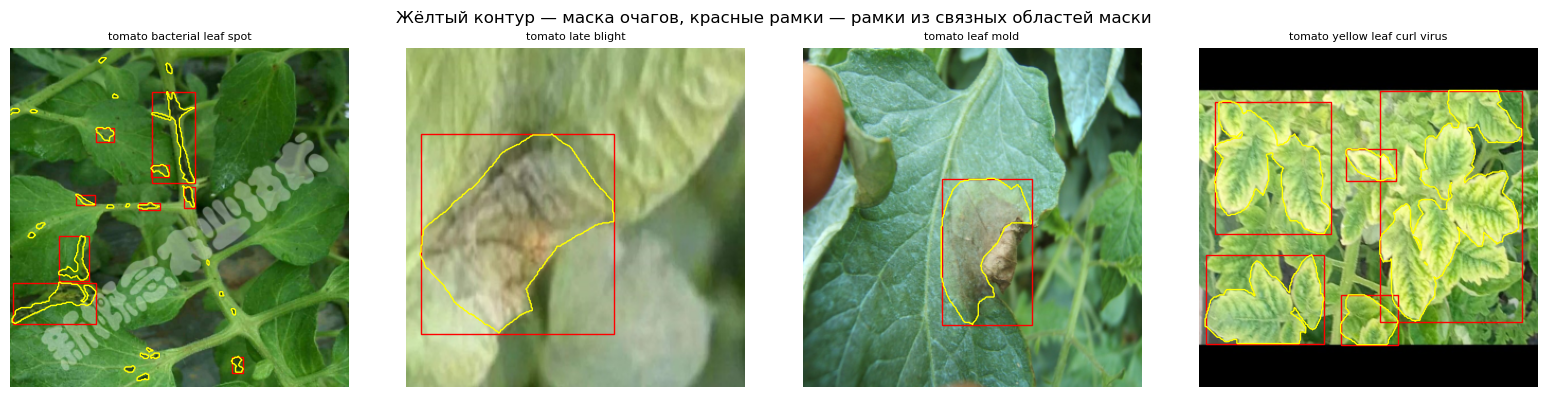

In [3]:
S = IMG_SIZE

def load_sample(img_path, mask_path):
    im = Image.open(img_path).convert('RGB').resize((S, S), Image.BILINEAR)
    m = np.array(Image.open(mask_path))
    if m.ndim == 3:
        m = m[..., 0]
    m = np.array(Image.fromarray((m > 0).astype('uint8')).resize((S, S), Image.NEAREST)).astype(bool)
    return np.array(im), m

def mask_to_boxes(mask):
    lab, n = cc_label(mask)
    boxes = []
    for i, sl in enumerate(find_objects(lab), 1):
        if sl is None:
            continue
        area = int((lab[sl] == i).sum())
        if area >= MIN_BOX_FRAC * S * S:
            boxes.append((sl[1].start, sl[0].start, sl[1].stop, sl[0].stop))
    return np.array(boxes, dtype=np.float32).reshape(-1, 4)

t0 = time.perf_counter()
data = {}
for split in (['train', 'val', 'test'] if need_train else ['test']):
    sub = meta[meta.split == split].reset_index(drop=True)
    ims, mks, bxs = [], [], []
    for r in sub.itertuples():
        im, mk = load_sample(r.img_path, r.mask_path)
        ims.append(im); mks.append(mk); bxs.append(mask_to_boxes(mk))
    data[split] = {'meta': sub, 'images': np.stack(ims), 'masks': np.stack(mks),
                   'boxes': bxs, 'labels': sub.label.to_numpy()}
print(f'Загрузка данных: {time.perf_counter() - t0:.1f} с')
display(pd.DataFrame({s: {'снимков': len(d['labels']),
                          'средняя доля очага на снимке': d['masks'].mean(),
                          'рамок на снимок': np.mean([len(b) for b in d['boxes']])}
                      for s, d in data.items()}).T.round(3))
ref = 'train' if 'train' in data else 'test'
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, i in zip(axes, np.linspace(0, len(data[ref]['labels']) - 1, 4).astype(int)):
    ax.imshow(data[ref]['images'][i])
    ax.contour(data[ref]['masks'][i], levels=[0.5], colors='yellow', linewidths=1)
    for x1, y1, x2, y2 in data[ref]['boxes'][i]:
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor='red', linewidth=1))
    ax.set_title(class_names[data[ref]['labels'][i]], fontsize=8); ax.axis('off')
plt.suptitle('Жёлтый контур — маска очагов, красные рамки — рамки из связных областей маски')
plt.tight_layout(); plt.show()

### Шаг 4. Функции метрик
Здесь определены все вычисления метрик. Подробное объяснение каждой метрики дано в разделах 3–5 рядом с результатами.

In [4]:
IOU_THRESHOLDS = np.round(np.arange(0.5, 0.96, 0.05), 2)

def iou_box(a, b):
    """IoU двух рамок (x1, y1, x2, y2): площадь пересечения / площадь объединения."""
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0

def match(preds, gts, thr):
    """preds: список (номер_снимка, уверенность, рамка); gts: словарь номер_снимка -> рамки.
    Рамки перебираются по убыванию уверенности; каждая сопоставляется со свободной эталонной рамкой
    с наибольшим IoU. Если IoU >= thr, это TP, иначе FP. Возвращает (уверенности, флаги TP, множество найденных эталонов)."""
    order = sorted(preds, key=lambda p: -p[1])
    used = {i: np.zeros(len(b), bool) for i, b in gts.items()}
    scores, tp, matched = [], [], set()
    for img, score, box in order:
        best, best_j = 0.0, -1
        for j, g in enumerate(gts.get(img, [])):
            if used[img][j]:
                continue
            v = iou_box(box, g)
            if v > best:
                best, best_j = v, j
        hit = best >= thr
        if hit:
            used[img][best_j] = True
            matched.add((img, best_j))
        scores.append(score); tp.append(1.0 if hit else 0.0)
    return np.array(scores), np.array(tp), matched

def average_precision(tp, n_gt):
    """AP: площадь под кривой precision-recall (монотонная огибающая). Возвращает (AP, recall, precision)."""
    if len(tp) == 0 or n_gt == 0:
        return 0.0, np.array([0.0]), np.array([1.0])
    ctp, cfp = np.cumsum(tp), np.cumsum(1 - tp)
    rec, prec = ctp / n_gt, ctp / (ctp + cfp)
    mrec, mpre = np.r_[0.0, rec, 1.0], np.r_[0.0, prec, 0.0]
    for i in range(len(mpre) - 2, -1, -1):
        mpre[i] = max(mpre[i], mpre[i + 1])
    idx = np.flatnonzero(mrec[1:] != mrec[:-1])
    return float(np.sum((mrec[idx + 1] - mrec[idx]) * mpre[idx + 1])), rec, prec

def det_ap(preds, gts, thr):
    n_gt = sum(len(b) for b in gts.values())
    _, tp, _ = match(preds, gts, thr)
    return average_precision(tp, n_gt)[0]

def seg_metrics(gt, pr):
    """Метрики сегментации одного снимка по пикселям."""
    tp = int((gt & pr).sum()); fp = int((~gt & pr).sum()); fn = int((gt & ~pr).sum()); tn = int((~gt & ~pr).sum())
    empty = tp + fp + fn == 0
    return {'tp': tp, 'fp': fp, 'fn': fn, 'tn': tn,
            'dice': 1.0 if empty else 2 * tp / (2 * tp + fp + fn),
            'iou': 1.0 if empty else tp / (tp + fp + fn),
            'pixel_acc': (tp + tn) / gt.size,
            'precision': tp / max(tp + fp, 1), 'recall': tp / max(tp + fn, 1)}

assert abs(iou_box((0, 0, 10, 10), (5, 0, 15, 10)) - 1 / 3) < 1e-9
print('Функции метрик готовы')

Функции метрик готовы


## 2. Ответы моделей

### Шаг 5. Определение моделей и обучения

Как обучается каждая модель:
- **Классификация.** Замороженная ResNet-18 превращает снимок в вектор признаков, на них обучается один линейный слой (30 эпох). Лучшая эпоха выбирается по macro-F1 на Validation.
- **Сегментация.** LR-ASPP на MobileNetV3, 15 эпох. Функция потерь — сумма кросс-энтропии и Dice-потерь: очаги занимают малую часть снимка, и одна кросс-энтропия приводит к пустым маскам. Лучшая эпоха — по среднему Dice на Validation.
- **Детекция.** Faster R-CNN на MobileNetV3, 12 эпох. Два класса: фон и очаг. Лучшая эпоха — по AP@0.5 на Validation.
- Для сегментации и детекции используется отражение снимка по горизонтали как простая аугментация.

In [5]:
def train_classifier():
    import torch
    from torch import nn
    import torch.nn.functional as F
    from torchvision import models
    dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    mean_t = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
    std_t = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
    def to_input(b):
        return (torch.from_numpy(b).permute(0, 3, 1, 2).float() / 255.0 - mean_t) / std_t
    t_all = time.perf_counter()
    torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
    bb = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    bb.fc = nn.Identity(); bb.requires_grad_(False); bb = bb.to(dev).eval()
    feats = {}
    with torch.inference_mode():
        for s in ['train', 'val', 'test']:
            arr = data[s]['images']
            feats[s] = torch.cat([bb(to_input(arr[i:i + 32]).to(dev)).cpu() for i in range(0, len(arr), 32)])
    t_feat = time.perf_counter() - t_all
    def probs(h, x):
        h.eval()
        with torch.no_grad():
            return h(x.to(dev)).softmax(1).cpu().numpy()
    head = nn.Linear(feats['train'].shape[1], K).to(dev)
    opt = torch.optim.Adam(head.parameters(), lr=1e-3)
    y_tr = torch.from_numpy(data['train']['labels']).long()
    best, best_state, best_epoch, curve = -1.0, None, 0, []
    for epoch in range(1, EPOCHS_CLS + 1):
        head.train()
        perm = torch.randperm(len(y_tr))
        for i in range(0, len(perm), 64):
            b = perm[i:i + 64]
            opt.zero_grad()
            F.cross_entropy(head(feats['train'][b].to(dev)), y_tr[b].to(dev)).backward()
            opt.step()
        sc = f1_score(data['val']['labels'], probs(head, feats['val']).argmax(1), labels=all_ids, average='macro', zero_division=0)
        curve.append(float(sc))
        if sc > best:
            best, best_epoch, best_state = sc, epoch, copy.deepcopy(head.state_dict())
    head.load_state_dict(best_state)
    info = {'best_epoch': best_epoch, 'best_val': round(float(best), 4), 'curve': curve,
            'seconds': round(time.perf_counter() - t_all, 1), 'seconds_features': round(t_feat, 1),
            'params': int(sum(p.numel() for p in head.parameters()) + sum(p.numel() for p in bb.parameters()))}
    print(f'Классификация: лучшая эпоха {best_epoch}, validation macro-F1 = {best:.4f}, время {info["seconds"]} с')
    return probs(head, feats['test']), info


def train_segmentation():
    import torch
    from torch import nn
    import torch.nn.functional as F
    from torchvision.models.segmentation import lraspp_mobilenet_v3_large, LRASPP_MobileNet_V3_Large_Weights
    dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    mean_t = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
    std_t = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
    def to_input(b):
        return (torch.from_numpy(b).permute(0, 3, 1, 2).float() / 255.0 - mean_t) / std_t
    torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
    m = lraspp_mobilenet_v3_large(weights=LRASPP_MobileNet_V3_Large_Weights.COCO_WITH_VOC_LABELS_V1)
    m.classifier.low_classifier = nn.Conv2d(m.classifier.low_classifier.in_channels, 2, 1)
    m.classifier.high_classifier = nn.Conv2d(m.classifier.high_classifier.in_channels, 2, 1)
    m = m.to(dev)
    def loss_fn(logits, target):
        ce = F.cross_entropy(logits, target)
        p, t = logits.softmax(1)[:, 1], target.float()
        inter = (p * t).sum((1, 2))
        return ce + (1 - (2 * inter + 1) / (p.sum((1, 2)) + t.sum((1, 2)) + 1)).mean()
    def predict(images, bs=16):
        m.eval(); out = []
        with torch.inference_mode():
            for i in range(0, len(images), bs):
                out.append((m(to_input(images[i:i + bs]).to(dev))['out'].argmax(1) == 1).cpu().numpy())
        return np.concatenate(out)
    def mean_dice(pred, gt):
        return float(np.mean([seg_metrics(g, p)['dice'] for g, p in zip(gt, pred)]))
    opt = torch.optim.AdamW(m.parameters(), lr=3e-4)
    n_tr = len(data['train']['labels'])
    t_all = time.perf_counter()
    best, best_state, best_epoch, curve, secs = -1.0, None, 0, [], []
    for epoch in range(1, EPOCHS_SEG + 1):
        te = time.perf_counter(); m.train()
        perm = np.random.permutation(n_tr)
        for i in range(0, n_tr, BATCH_SEG):
            b = np.sort(perm[i:i + BATCH_SEG])
            if len(b) < 2:
                continue
            x = to_input(data['train']['images'][b]).to(dev)
            y = torch.from_numpy(data['train']['masks'][b].astype(np.int64)).to(dev)
            if random.random() < 0.5:
                x, y = x.flip(-1), y.flip(-1)
            opt.zero_grad(); loss_fn(m(x)['out'], y).backward(); opt.step()
        d = mean_dice(predict(data['val']['images']), data['val']['masks'])
        curve.append(round(d, 4)); secs.append(round(time.perf_counter() - te, 1))
        print(f'Сегментация, эпоха {epoch}/{EPOCHS_SEG}: validation Dice = {d:.4f} ({secs[-1]} с)')
        if d > best:
            best, best_epoch, best_state = d, epoch, copy.deepcopy(m.state_dict())
    m.load_state_dict(best_state)
    t_tot = time.perf_counter() - t_all
    t0 = time.perf_counter(); pred = predict(data['test']['images']); t_inf = time.perf_counter() - t0
    info = {'best_epoch': best_epoch, 'best_val': round(float(best), 4), 'curve': curve, 'epoch_seconds': secs,
            'seconds': round(t_tot, 1), 'inference_ms_per_image': round(1000 * t_inf / len(pred), 1),
            'params': int(sum(p.numel() for p in m.parameters()))}
    return pred, info


def train_detection():
    import torch
    from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_320_fpn, FasterRCNN_MobileNet_V3_Large_320_FPN_Weights
    from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
    dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
    m = fasterrcnn_mobilenet_v3_large_320_fpn(weights=FasterRCNN_MobileNet_V3_Large_320_FPN_Weights.COCO_V1)
    m.roi_heads.box_predictor = FastRCNNPredictor(m.roi_heads.box_predictor.cls_score.in_features, 2)
    m = m.to(dev)
    def tens(a):
        return torch.from_numpy(a).permute(2, 0, 1).float() / 255.0
    def predict(images, bs=8):
        m.eval(); preds = []
        with torch.inference_mode():
            for i in range(0, len(images), bs):
                outs = m([tens(a).to(dev) for a in images[i:i + bs]])
                for j, o in enumerate(outs):
                    for box, sc in zip(o['boxes'].cpu().numpy(), o['scores'].cpu().numpy()):
                        preds.append((i + j, float(sc), tuple(float(v) for v in box)))
        return preds
    val_gts = {i: b for i, b in enumerate(data['val']['boxes'])}
    train_ids = [i for i, b in enumerate(data['train']['boxes']) if len(b) > 0]
    opt = torch.optim.SGD([p for p in m.parameters() if p.requires_grad], lr=0.005, momentum=0.9, weight_decay=5e-4)
    t_all = time.perf_counter()
    best, best_state, best_epoch, curve, secs = -1.0, None, 0, [], []
    for epoch in range(1, EPOCHS_DET + 1):
        te = time.perf_counter(); m.train()
        perm = np.random.permutation(train_ids)
        for i in range(0, len(perm), BATCH_DET):
            imgs, tgts = [], []
            for k in perm[i:i + BATCH_DET]:
                im = tens(data['train']['images'][k]); bx = torch.from_numpy(data['train']['boxes'][k]).clone()
                if random.random() < 0.5:
                    im = im.flip(-1); bx[:, [0, 2]] = S - bx[:, [2, 0]]
                imgs.append(im.to(dev))
                tgts.append({'boxes': bx.to(dev), 'labels': torch.ones(len(bx), dtype=torch.int64, device=dev)})
            opt.zero_grad(); sum(m(imgs, tgts).values()).backward(); opt.step()
        ap = det_ap(predict(data['val']['images']), val_gts, 0.5)
        curve.append(round(ap, 4)); secs.append(round(time.perf_counter() - te, 1))
        print(f'Детекция, эпоха {epoch}/{EPOCHS_DET}: validation AP@0.5 = {ap:.4f} ({secs[-1]} с)')
        if ap > best:
            best, best_epoch, best_state = ap, epoch, copy.deepcopy(m.state_dict())
    m.load_state_dict(best_state)
    t_tot = time.perf_counter() - t_all
    t0 = time.perf_counter(); preds = predict(data['test']['images']); t_inf = time.perf_counter() - t0
    info = {'best_epoch': best_epoch, 'best_val': round(float(best), 4), 'curve': curve, 'epoch_seconds': secs,
            'seconds': round(t_tot, 1), 'inference_ms_per_image': round(1000 * t_inf / len(data['test']['labels']), 1),
            'params': int(sum(p.numel() for p in m.parameters()))}
    return preds, info
print('Функции обучения определены')

Функции обучения определены


### Шаг 6. Получение ответов моделей на Test
Если есть `predictions.pkl` и `RETRAIN = False`, ответы загружаются из файла. Иначе три модели обучаются и их ответы сохраняются в `predictions.pkl`.

In [6]:
if need_train:
    prob_test, info_cls = train_classifier()
    pred_masks_test, info_seg = train_segmentation()
    det_preds_test, info_det = train_detection()
    INFO = {'cls': info_cls, 'seg': info_seg, 'det': info_det}
    with open(CACHE, 'wb') as f:
        pickle.dump({'prob_test': prob_test, 'pred_masks_test': pred_masks_test, 'det_preds_test': det_preds_test,
                     'classes': class_names, 'test_names': data['test']['meta']['Name'].tolist(), 'info': INFO}, f)
    print('Ответы моделей сохранены в', CACHE)
else:
    with open(CACHE, 'rb') as f:
        cache = pickle.load(f)
    assert cache['classes'] == class_names, 'Список классов в файле не совпадает с текущим'
    assert cache['test_names'] == data['test']['meta']['Name'].tolist(), 'Порядок тестовых снимков в файле не совпадает'
    prob_test, pred_masks_test, det_preds_test, INFO = (cache['prob_test'], cache['pred_masks_test'],
                                                        cache['det_preds_test'], cache['info'])
    print('Готовые ответы моделей загружены')

def fmt(v, unit=''):
    return 'не фиксировалось' if v is None else f'{v}{unit}'
display(pd.DataFrame({
    'лучшая эпоха': {k: INFO[k]['best_epoch'] for k in INFO},
    'метрика выбора на Validation': {'cls': 'macro-F1', 'seg': 'Dice', 'det': 'AP@0.5'},
    'значение на Validation': {k: INFO[k]['best_val'] for k in INFO},
    'время обучения, с': {k: fmt(INFO[k].get('seconds')) for k in INFO},
    'параметров модели': {k: fmt(INFO[k].get('params')) for k in INFO}}).rename(
        index={'cls': 'классификация', 'seg': 'сегментация', 'det': 'детекция'}))

Готовые ответы моделей загружены


,лучшая эпоха,метрика выбора на Validation,значение на Validation,"время обучения, с",параметров модели
классификация,29,macro-F1,0.6212,не фиксировалось,не фиксировалось
сегментация,14,Dice,0.6461,не фиксировалось,не фиксировалось
детекция,5,AP@0.5,0.1676,не фиксировалось,не фиксировалось


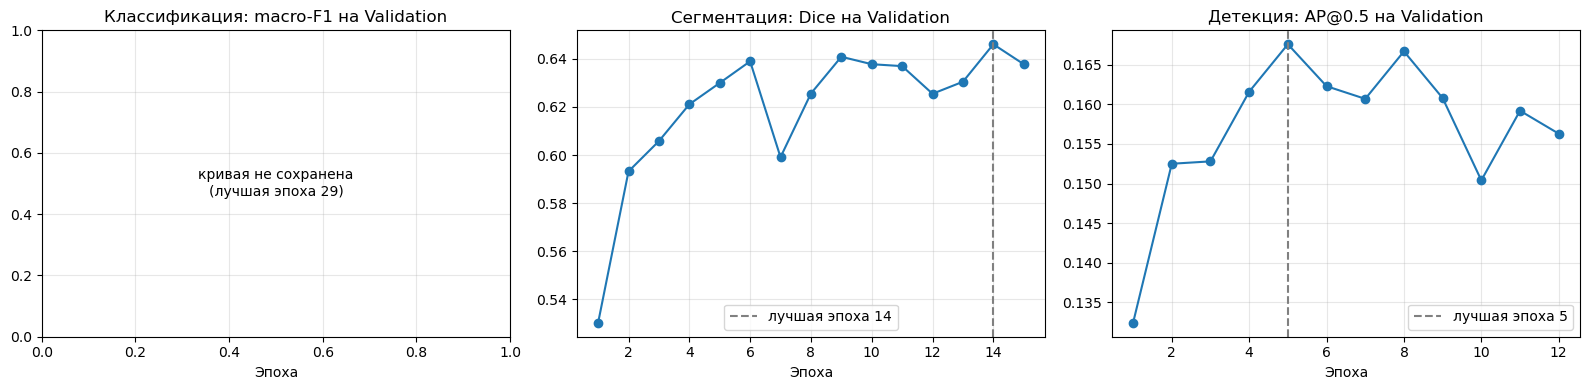

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
titles = {'cls': 'Классификация: macro-F1 на Validation',
          'seg': 'Сегментация: Dice на Validation',
          'det': 'Детекция: AP@0.5 на Validation'}
for ax, k in zip(axes, ['cls', 'seg', 'det']):
    curve = INFO[k].get('curve')
    if curve:
        ax.plot(range(1, len(curve) + 1), curve, marker='o')
        ax.axvline(INFO[k]['best_epoch'], color='gray', linestyle='--',
                   label=f"лучшая эпоха {INFO[k]['best_epoch']}")
        ax.legend()
    else:
        ax.text(0.5, 0.5, 'кривая не сохранена\n(лучшая эпоха %d)' % INFO[k]['best_epoch'],
                ha='center', va='center')
    ax.set(title=titles[k], xlabel='Эпоха'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

#### Как шло обучение
Каждая точка — значение метрики на Validation после очередной эпохи. Пунктир — эпоха, веса которой использованы дальше.
Сегментация: в первые пять эпох Dice быстро растёт (0.53 → 0.63), потом колеблется в диапазоне 0.60–0.65: модель вышла на плато, и «лучшая» эпоха 14 мало отличается от соседних.
Детекция: AP@0.5 растёт до пятой эпохи (0.13 → 0.17), дальше колеблется в диапазоне 0.15–0.17: дальнейшее обучение улучшения не дало.
Классификация: кривая в этом запуске не сохранена, известна только лучшая эпоха (29 из 30).

### Контроль
Пояснения в блоках «Как читать результат» написаны для конкретного запуска, чьи ответы моделей сохранены в `predictions.pkl`. Ячейка ниже пересчитывает три главных числа и сверяет их с теми, на которые ссылается текст. Если вы заново обучили модели, числа изменятся и пояснения нужно читать как образец рассуждения.

In [7]:
y_test = data['test']['labels']
pred_cls = prob_test.argmax(1)
_acc = accuracy_score(y_test, pred_cls)
_dice = float(np.mean([seg_metrics(g, p)['dice'] for g, p in zip(data['test']['masks'], pred_masks_test)]))
_gts = {i: b for i, b in enumerate(data['test']['boxes'])}
_ap50 = det_ap(det_preds_test, _gts, 0.5)
EXPECTED = {'accuracy': 0.6022, 'Dice (среднее по снимкам)': 0.6304, 'AP@0.5': 0.1651}
got = {'accuracy': _acc, 'Dice (среднее по снимкам)': _dice, 'AP@0.5': _ap50}
for k in EXPECTED:
    ok = abs(got[k] - EXPECTED[k]) < 0.002
    print(f'{k}: {got[k]:.4f} (в пояснениях {EXPECTED[k]}) -> {"совпадает" if ok else "ОТЛИЧАЕТСЯ: числа в пояснениях относятся к другому запуску"}')

accuracy: 0.6022 (в пояснениях 0.6022) -> совпадает
Dice (среднее по снимкам): 0.6304 (в пояснениях 0.6304) -> совпадает
AP@0.5: 0.1651 (в пояснениях 0.1651) -> совпадает


## 3. Классификация: какую болезнь видит модель

### Шаг 7. Ошибки по классам и основные метрики
Сначала по матрице ошибок считаем для каждой болезни три числа:
- **TP** — снимки этой болезни, которые модель назвала верно;
- **FN** — снимки этой болезни, которые модель назвала другой болезнью (пропуск);
- **FP** — снимки других болезней, которые модель назвала этой болезнью (ложный диагноз).

Из них получаются метрики по классу: **recall** = TP/(TP+FN) — какую долю настоящих случаев модель нашла; **precision** = TP/(TP+FP) — какая доля названных диагнозов верна; **F1** — среднее гармоническое precision и recall (оно мало, если мало любое из двух).

,снимков в тесте,модель назвала так,TP,FN,FP,precision,recall,F1
tomato bacterial leaf spot,22,9,5,17,4,0.556,0.227,0.323
tomato early blight,37,32,23,14,9,0.719,0.622,0.667
tomato late blight,33,36,23,10,13,0.639,0.697,0.667
tomato leaf mold,31,39,24,7,15,0.615,0.774,0.686
tomato mosaic virus,13,9,3,10,6,0.333,0.231,0.273
tomato septoria leaf spot,26,32,15,11,17,0.469,0.577,0.517
tomato yellow leaf curl virus,19,24,16,3,8,0.667,0.842,0.744


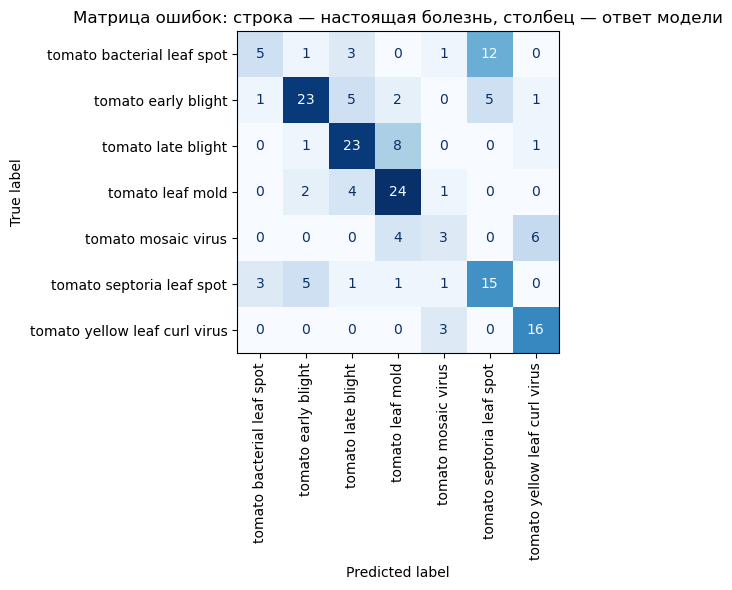

,значение
accuracy,0.6022
balanced accuracy (macro recall),0.5671
macro-F1,0.5537
weighted-F1,0.5865


In [9]:
cm = confusion_matrix(y_test, pred_cls, labels=all_ids)
tp_c = np.diag(cm); fn_c = cm.sum(1) - tp_c; fp_c = cm.sum(0) - tp_c
counts = pd.DataFrame({'снимков в тесте': cm.sum(1), 'модель назвала так': cm.sum(0),
                       'TP': tp_c, 'FN': fn_c, 'FP': fp_c,
                       'precision': tp_c / np.maximum(tp_c + fp_c, 1), 'recall': tp_c / np.maximum(tp_c + fn_c, 1)},
                      index=class_names)
counts['F1'] = 2 * counts.precision * counts.recall / np.maximum(counts.precision + counts.recall, 1e-9)
display(counts.round(3))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap='Blues', xticks_rotation=90, colorbar=False)
ax.set_title('Матрица ошибок: строка — настоящая болезнь, столбец — ответ модели')
plt.tight_layout(); plt.show()

p_, r_, f_, s_ = precision_recall_fscore_support(y_test, pred_cls, labels=all_ids, zero_division=0)
_, _, fw_, _ = precision_recall_fscore_support(y_test, pred_cls, labels=all_ids, average='weighted', zero_division=0)
overall = pd.Series({'accuracy': accuracy_score(y_test, pred_cls), 'balanced accuracy (macro recall)': r_.mean(),
                     'macro-F1': f_.mean(), 'weighted-F1': fw_}).round(4)
display(overall.to_frame('значение'))
counts.join(pd.Series(s_, index=class_names, name='support')).to_csv(OUT_DIR / 'classification_by_class.csv')

#### Как читать результат (классификация, основные метрики)

**Пример по одной болезни.** В тесте 22 снимка bacterial leaf spot. Модель назвала так 9 снимков, из них верно 5. Значит TP = 5, FN = 17, FP = 4. Recall = 5/22 ≈ 0.23: из 22 настоящих случаев найдено меньше четверти. Precision = 5/9 ≈ 0.56: когда модель говорит «bacterial», она права немногим чаще, чем в половине случаев. F1 = 0.32 низкая, потому что низок recall.

**Что значат precision и recall в разных строках.**
- Precision выше recall (bacterial leaf spot, mosaic virus, early blight): модель осторожна — редко называет эту болезнь, но чаще права, когда называет.
- Recall выше precision (leaf mold, septoria leaf spot, yellow leaf curl virus): модель щедро ставит этот диагноз, находит большую часть настоящих случаев, но и ошибается чаще (septoria: названа 32 раза при 26 настоящих случаях).

**Accuracy, macro и weighted.**
- Accuracy — доля верных ответов на всех 181 снимках: 109/181 = 0.60. Болезнь с малым числом снимков влияет на неё мало.
- Macro-F1 — простое среднее F1 по семи болезням, каждая болезнь вносит 1/7. Weighted-F1 — среднее с весами по числу снимков. Balanced accuracy — среднее recall по болезням.
- Macro-F1 (0.55) ниже accuracy (0.60), потому что две плохо распознаваемые болезни — bacterial leaf spot (F1 0.32) и mosaic virus (F1 0.27) — в accuracy весят по доле снимков (35 из 181, около 19%), а в macro — по 1/7 каждая (около 29% вместе). Macro сильнее «наказывает» за провал на редких и трудных болезнях.

**Практический смысл.** Если важно не пропускать каждую болезнь (в защите растений это обычно так), смотрите recall и F1 по классам и macro-F1. Accuracy на неравных классах скрывает слабые классы.

### Шаг 8. Оценка качества вероятностей: ROC-AUC и average precision
Модель для каждого снимка выдаёт семь вероятностей — по одной на болезнь. Accuracy использует только самую большую из них (argmax). ROC-AUC и AP используют сами вероятности и для каждой болезни отвечают на вопрос «насколько хорошо вероятность этой болезни отделяет снимки с ней от снимков без неё».

- **ROC-AUC** (по схеме «одна болезнь против остальных»): берём случайный снимок с этой болезнью и случайный без неё; AUC — вероятность того, что у первого вероятность этой болезни выше. 0.5 — случайное угадывание, 1.0 — идеал.
- **Average precision (AP)**: средняя точность по всем порогам вероятности; её случайный уровень равен доле болезни в тесте.

Также считается доверительный интервал accuracy и macro-F1: тест перемешивается с повторами (бутстреп) 1000 раз, берётся диапазон, в который попадает 95% значений.

In [10]:
ovr = pd.DataFrame({'снимков': [int((y_test == c).sum()) for c in all_ids],
                    'доля в тесте': [float((y_test == c).mean()) for c in all_ids],
                    'ROC-AUC': [roc_auc_score((y_test == c).astype(int), prob_test[:, c]) for c in all_ids],
                    'AP': [average_precision_score((y_test == c).astype(int), prob_test[:, c]) for c in all_ids]},
                   index=class_names)
ovr['AP / доля в тесте'] = ovr['AP'] / ovr['доля в тесте']
display(ovr.round(3))
print(f'ROC-AUC (среднее по болезням): {ovr["ROC-AUC"].mean():.3f}')
rng = np.random.default_rng(SEED)
bs = []
for _ in range(1000):
    i = rng.integers(0, len(y_test), len(y_test))
    p, r, f, _ = precision_recall_fscore_support(y_test[i], pred_cls[i], labels=all_ids, zero_division=0)
    bs.append([accuracy_score(y_test[i], pred_cls[i]), f.mean()])
lo, hi = np.percentile(np.array(bs), [2.5, 97.5], axis=0)
print(f'accuracy = {accuracy_score(y_test, pred_cls):.3f}, 95% интервал [{lo[0]:.3f}; {hi[0]:.3f}]')
print(f'macro-F1 = {f_.mean():.3f}, 95% интервал [{lo[1]:.3f}; {hi[1]:.3f}]')
ovr.to_csv(OUT_DIR / 'classification_ovr.csv')

,снимков,доля в тесте,ROC-AUC,AP,AP / доля в тесте
tomato bacterial leaf spot,22,0.122,0.877,0.511,4.206
tomato early blight,37,0.204,0.933,0.767,3.752
tomato late blight,33,0.182,0.938,0.799,4.384
tomato leaf mold,31,0.171,0.933,0.752,4.393
tomato mosaic virus,13,0.072,0.888,0.330,4.598
tomato septoria leaf spot,26,0.144,0.884,0.530,3.692
tomato yellow leaf curl virus,19,0.105,0.973,0.753,7.170


ROC-AUC (среднее по болезням): 0.918
accuracy = 0.602, 95% интервал [0.525; 0.674]
macro-F1 = 0.554, 95% интервал [0.471; 0.625]


#### Как читать результат (ROC-AUC, AP, интервалы)

**Почему AUC высок (0.92), а accuracy низка (0.60).** Это ответы на разные вопросы. AUC для болезни сравнивает снимки с ней и без неё только по вероятности этой одной болезни. Чтобы засчитался верный ответ, этого мало: вероятность нужной болезни на снимке должна оказаться больше всех шести остальных вероятностей на том же снимке. Модель довольно хорошо отделяет «эта болезнь» от «не эта», но болезни между собой путает, поэтому AUC высок, а accuracy нет.

**Что даёт AP.** Для болезни, которая встречается редко, AUC может оставаться высоким, а AP быстро падает: AP учитывает, насколько точны самые уверенные ответы. Сравнивать AP между болезнями удобно через отношение AP к доле болезни в тесте: у большинства болезней оно около 4, у yellow leaf curl virus выше 7 — эта болезнь отделяется лучше всех. У mosaic virus и bacterial leaf spot AUC почти одинаков (0.89 и 0.88), а AP заметно разный (0.33 и 0.51): AP зависит от доли болезни в тесте (7% и 12%).

**Интервалы.** Тест маленький: 181 снимок. Интервал accuracy шириной около 15 процентных пунктов (от 0.52 до 0.67) говорит: на другом наборе снимков тот же классификатор мог бы получить любое значение из этого диапазона. Две модели с accuracy 0.60 и 0.63 на таком тесте различить нельзя. По отдельной болезни ещё хуже: у mosaic virus всего 13 снимков, один снимок меняет recall на 7.7 п.п. (3 из 13 найдено).

## 4. Сегментация: где на снимке очаги

### Шаг 9. Метрики по пикселям
Для каждого снимка сравниваются эталонная маска (где очаги на самом деле) и маска модели. Каждый пиксель попадает в одну из четырёх групп: TP (очаг и модель сказала очаг), FP (фон, но модель сказала очаг), FN (очаг, но модель сказала фон), TN (фон и модель сказала фон).

- **Dice** = 2·TP / (2·TP + FP + FN) — удвоенная площадь пересечения, делённая на сумму площадей двух масок. 1 — полное совпадение, 0 — нет общих пикселей.
- **IoU** = TP / (TP + FP + FN) — пересечение, делённое на объединение; строже Dice.
- **Pixel accuracy** = (TP + TN) / все пиксели — доля пикселей, для которых модель угадала «очаг» или «фон». В неё входит фон.

Есть два способа получить одно число по всему тесту: **среднее по снимкам** (считаем метрику на каждом снимке и усредняем, все снимки равноправны) и **по всем пикселям** (складываем TP, FP, FN, TN со всех снимков и считаем один раз, крупные очаги весят больше).

In [11]:
gt_masks_test = data['test']['masks']
rows = []
for gt, pr in zip(gt_masks_test, pred_masks_test):
    m = seg_metrics(gt, pr)
    m['mask_ratio'] = gt.mean()
    rows.append(m)
seg_df = pd.DataFrame(rows)
tp, fp, fn, tn = (seg_df[c].sum() for c in ['tp', 'fp', 'fn', 'tn'])
summary = pd.DataFrame({
    'среднее по снимкам': seg_df[['dice', 'iou', 'pixel_acc', 'precision', 'recall']].mean(),
    'по всем пикселям': pd.Series({'dice': 2 * tp / (2 * tp + fp + fn), 'iou': tp / (tp + fp + fn),
                                  'pixel_acc': (tp + tn) / (tp + tn + fp + fn),
                                  'precision': tp / max(tp + fp, 1), 'recall': tp / max(tp + fn, 1)})})
display(summary.round(4))
empty_baseline = 1 - gt_masks_test.mean()
print(f'Пустая маска («очагов нет» на всех снимках): pixel accuracy = {empty_baseline:.3f}, Dice = 0')
print(f'Связь IoU = D/(2-D): по всем пикселям {summary.loc["dice", "по всем пикселям"]:.4f} -> '
      f'{summary.loc["dice", "по всем пикселям"] / (2 - summary.loc["dice", "по всем пикселям"]):.4f} (измерено {summary.loc["iou", "по всем пикселям"]:.4f}); '
      f'по снимкам {summary.loc["dice", "среднее по снимкам"]:.4f} -> '
      f'{summary.loc["dice", "среднее по снимкам"] / (2 - summary.loc["dice", "среднее по снимкам"]):.4f} (измерено {summary.loc["iou", "среднее по снимкам"]:.4f})')
summary.to_csv(OUT_DIR / 'segmentation_summary.csv')

,среднее по снимкам,по всем пикселям
dice,0.6304,0.6835
iou,0.4972,0.5191
pixel_acc,0.8901,0.8901
precision,0.6541,0.6879
recall,0.6891,0.6791


Пустая маска («очагов нет» на всех снимках): pixel accuracy = 0.825, Dice = 0
Связь IoU = D/(2-D): по всем пикселям 0.6835 -> 0.5191 (измерено 0.5191); по снимкам 0.6304 -> 0.4603 (измерено 0.4972)


#### Как читать результат (сегментация, общие числа)

**Два способа усреднения дают разные числа.** Dice по снимкам — 0.63, по всем пикселям — 0.68. Разница возникает потому, что крупные очаги модель сегментирует лучше мелких; при суммировании по пикселям они вносят больше пикселей, и общая оценка смещается к ним. Среднее по снимкам отвечает на вопрос «насколько хорошо в типичном случае», по пикселям — «какая доля всей площади очагов найдена верно».

**Связь Dice и IoU.** Для суммарных чисел (по всем пикселям) выполняется IoU = Dice / (2 − Dice): 0.684 даёт 0.519, как и измерено. Для средних по снимкам формула не работает (из 0.630 получилось бы 0.460, а измерено 0.497): среднее значение IoU не равно значению формулы от среднего Dice, потому что формула нелинейна.

**Что такое «пустая маска» и зачем она в таблице.** Самый простой ответ «очагов нигде нет» верен для всех фоновых пикселей. Здесь на фон приходится 82.5% всех пикселей, поэтому такая маска получила бы pixel accuracy 0.825 — почти как у обученной модели (0.890). Pixel accuracy у модели лишь на 6.5 п.п. выше бесполезного ответа, а Dice у пустой маски равен 0 и сразу показывает, что очаги не найдены. Поэтому для задач, где объект занимает малую часть снимка, pixel accuracy использовать как основную метрику нельзя.

### Шаг 10. Зависимость от размера очага
Снимки разбиты на четыре равные по числу группы по доле площади, занятой очагами (Q1 — самые мелкие очаги, Q4 — самые крупные).

,доля очага,Dice,IoU,Pixel accuracy,Precision,Recall
группа по размеру очага,,,,,,
Q1 (мелкие),0.039,0.528,0.400,0.951,0.507,0.663
Q2,0.097,0.629,0.488,0.911,0.599,0.724
Q3,0.178,0.671,0.530,0.885,0.701,0.699
Q4 (крупные),0.389,0.697,0.573,0.812,0.812,0.670


Корреляция Спирмена: (доля очага, Dice) = 0.303 | (доля очага, pixel accuracy) = -0.618


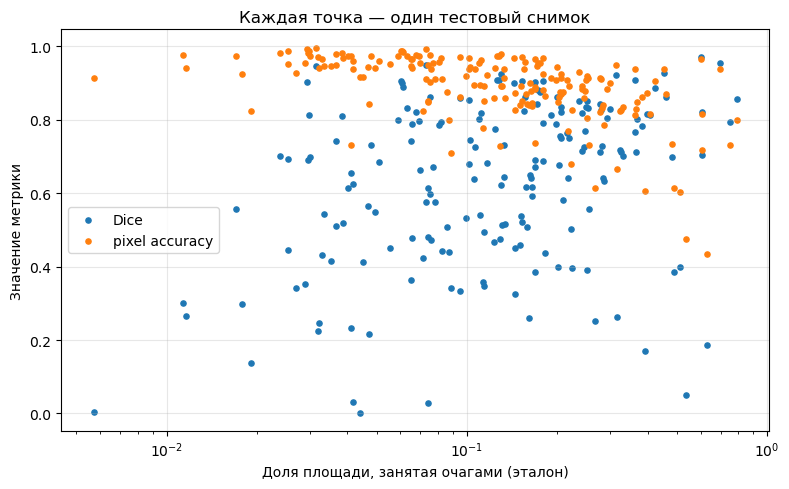

In [12]:
seg_df['группа по размеру очага'] = pd.qcut(seg_df.mask_ratio, 4, labels=['Q1 (мелкие)', 'Q2', 'Q3', 'Q4 (крупные)'])
size_table = seg_df.groupby('группа по размеру очага', observed=True)[['mask_ratio', 'dice', 'iou', 'pixel_acc', 'precision', 'recall']].mean()
size_table.columns = ['доля очага', 'Dice', 'IoU', 'Pixel accuracy', 'Precision', 'Recall']
display(size_table.round(3))
print('Корреляция Спирмена: (доля очага, Dice) =', round(spearmanr(seg_df.mask_ratio, seg_df.dice)[0], 3),
      '| (доля очага, pixel accuracy) =', round(spearmanr(seg_df.mask_ratio, seg_df.pixel_acc)[0], 3))
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(seg_df.mask_ratio, seg_df.dice, s=14, label='Dice')
ax.scatter(seg_df.mask_ratio, seg_df.pixel_acc, s=14, label='pixel accuracy')
ax.set_xscale('log'); ax.set(xlabel='Доля площади, занятая очагами (эталон)', ylabel='Значение метрики')
ax.set_title('Каждая точка — один тестовый снимок'); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()
size_table.to_csv(OUT_DIR / 'segmentation_by_size.csv')

#### Как читать результат (размер очага)

- **Dice растёт с размером очага** (от 0.53 у мелких до 0.70 у крупных). Обычное объяснение: ошибка на границе очага — несколько пикселей — составляет для мелкого очага большую долю его площади, чем для крупного.
- **Pixel accuracy ведёт себя наоборот** (от 0.95 у мелких до 0.81 у крупных), корреляция с размером отрицательная. Причина в самой метрике: у снимка с мелкими очагами почти все пиксели — фон, и модель «бесплатно» угадывает их. Чем больше очаг, тем меньше лёгкого фона и тем ниже pixel accuracy. Значение 0.95 у мелких очагов не означает, что модель их хорошо находит: Dice у них самый низкий.
- **Precision и recall по размеру.** У мелких очагов precision (0.51) ниже recall (0.66): модель рисует очаги шире и ложных пикселей больше, чем пропусков. У крупных очагов наоборот: precision 0.81, recall 0.67 — модель недорисовывает.

**Проверка эталонов.** Если на снимке маска-эталон явно не соответствует изображению (видно на примерах ниже), Dice на нём падает до нуля, хотя модель ни при чём.

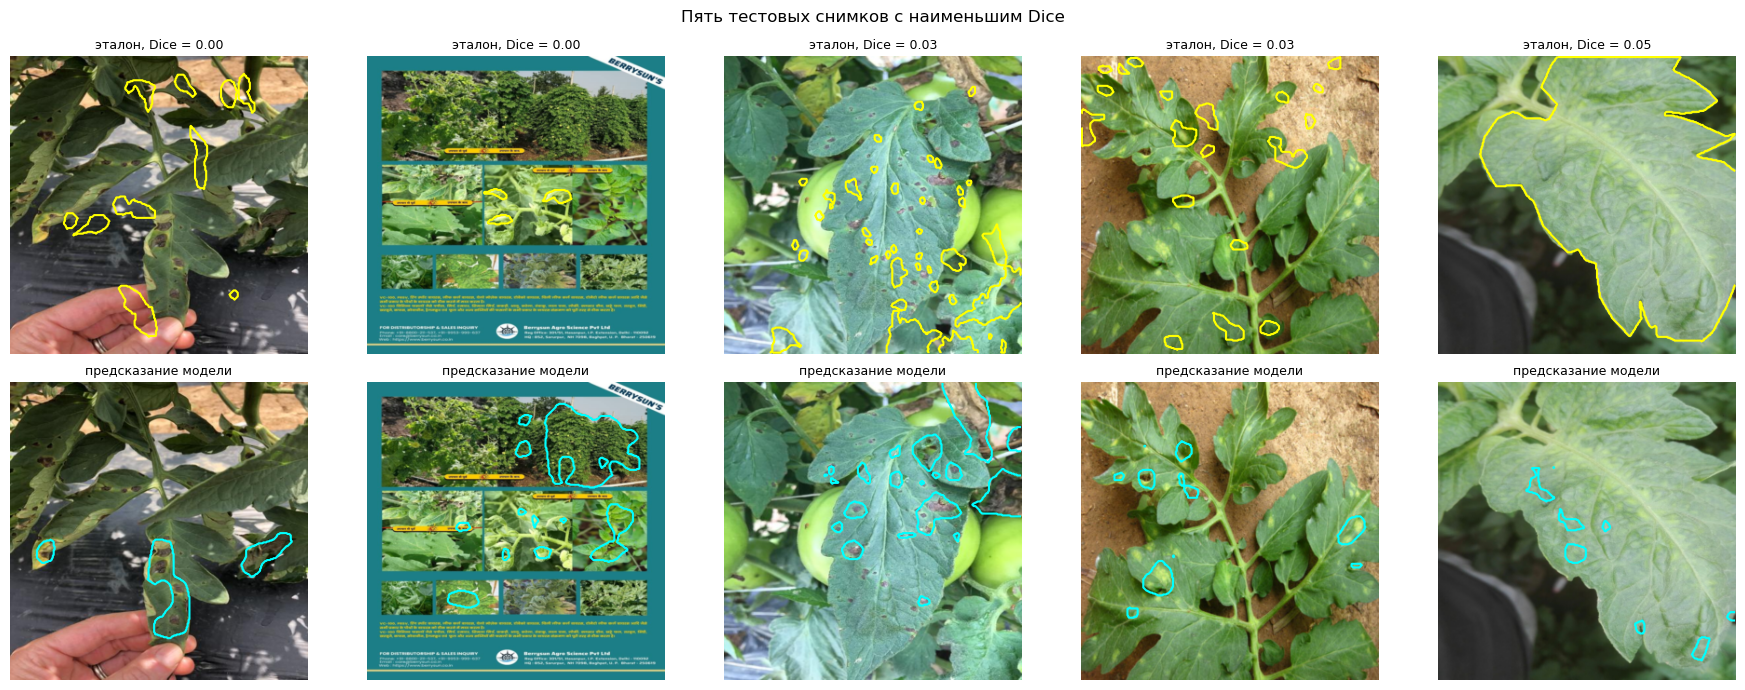

Эвристика: у очага «зелёность» ниже, чем у фона. Какое преобразование маски лучше совпадает с очагами:


,снимков
rot0,94
rot270,19
rot90+flip,15
rot90,14
rot180,14
rot270+flip,11
rot0+flip,9
rot180+flip,5


Если для большинства снимков лучшим оказывается rot0, маски в целом совпадают с изображениями; отдельные снимки с другим результатом — кандидаты на ошибку разметки (эвристика приблизительная).


In [13]:
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
worst = np.argsort(seg_df.dice.to_numpy())[:5]
for k, i in enumerate(worst):
    axes[0, k].imshow(data['test']['images'][i]); axes[0, k].contour(gt_masks_test[i], levels=[0.5], colors='yellow')
    axes[0, k].set_title(f'эталон, Dice = {seg_df.dice[i]:.2f}', fontsize=9)
    axes[1, k].imshow(data['test']['images'][i]); axes[1, k].contour(pred_masks_test[i], levels=[0.5], colors='cyan')
    axes[1, k].set_title('предсказание модели', fontsize=9)
    axes[0, k].axis('off'); axes[1, k].axis('off')
plt.suptitle('Пять тестовых снимков с наименьшим Dice')
plt.tight_layout(); plt.show()

def variants(m):
    out = {}
    for k in range(4):
        r = np.rot90(m, k)
        out[f'rot{k * 90}'] = r
        out[f'rot{k * 90}+flip'] = r[:, ::-1]
    return out

def contrast(img, m):
    if m.sum() == 0 or m.all():
        return np.nan
    g = img[..., 1] / (img.astype(np.float32).sum(-1) + 1e-6)
    return float(g[~m].mean() - g[m].mean())

al = pd.DataFrame([{k: contrast(img, v) for k, v in variants(m).items()}
                   for img, m in zip(data['test']['images'], gt_masks_test)])
best_v = al.idxmax(axis=1)
print('Эвристика: у очага «зелёность» ниже, чем у фона. Какое преобразование маски лучше совпадает с очагами:')
display(best_v.value_counts().to_frame('снимков'))
print('Если для большинства снимков лучшим оказывается rot0, маски в целом совпадают с изображениями; '
      'отдельные снимки с другим результатом — кандидаты на ошибку разметки (эвристика приблизительная).')

## 5. Детекция: рамки вокруг очагов

### Шаг 11. Как считаются TP, FP, FN у рамок
Модель выдаёт для каждого снимка набор рамок, у каждой есть **уверенность** (число от 0 до 1). Чтобы понять, верна ли рамка, её сравнивают с эталонными рамками по **IoU** — площади пересечения, делённой на площадь объединения. Рамка засчитывается верной (TP), если её IoU с ещё не занятой эталонной рамкой не меньше заданного порога IoU. Иначе это ложное срабатывание (FP). Эталонные рамки, которые никто не нашёл, — это FN.

В детекции есть **два разных порога**, их легко перепутать:
- **порог IoU** — насколько точно рамка должна совпасть с эталоном, чтобы считаться верной (0.5 — достаточно половинного перекрытия; 0.75 — нужно очень точное);
- **порог уверенности** — какие из выданных моделью рамок вообще оставить (рамки с уверенностью ниже порога отбрасываются).

Сначала зафиксируем порог IoU = 0.5 и посмотрим, как меняется результат при разных порогах уверенности.

In [14]:
test_gts = {i: b for i, b in enumerate(data['test']['boxes'])}
n_gt = sum(len(b) for b in test_gts.values())
rows = []
for conf in [0.05, 0.2, 0.35, 0.5, 0.65, 0.8]:
    kept = [p for p in det_preds_test if p[1] >= conf]
    _, tp_, _ = match(kept, test_gts, 0.5)
    TP = int(tp_.sum()); FP = len(kept) - TP; FN = n_gt - TP
    rows.append({'порог уверенности': conf, 'рамок оставлено': len(kept), 'TP': TP, 'FP': FP, 'FN': FN,
                 'precision': TP / max(TP + FP, 1), 'recall': TP / max(n_gt, 1), 'F1': 2 * TP / max(2 * TP + FP + FN, 1)})
conf_table = pd.DataFrame(rows)
print(f'Эталонных рамок в тесте: {n_gt}')
display(conf_table.round(3))
conf_table.to_csv(OUT_DIR / 'detection_confidence_thresholds.csv', index=False)

Эталонных рамок в тесте: 1447


,порог уверенности,рамок оставлено,TP,FP,FN,precision,recall,F1
0,0.05,3693,494,3199,953,0.134,0.341,0.192
1,0.20,1247,348,899,1099,0.279,0.240,0.258
2,0.35,627,269,358,1178,0.429,0.186,0.259
3,0.50,389,207,182,1240,0.532,0.143,0.225
4,0.65,234,149,85,1298,0.637,0.103,0.177
5,0.80,138,95,43,1352,0.688,0.066,0.120


#### Как читать результат (порог уверенности)

- При самом низком пороге (0.05) оставлены все рамки модели: найдено 494 из 1447 эталонных (recall 0.34), но среди выданных рамок верна лишь каждая седьмая (precision 0.13) — большинство лишних.
- При высоком пороге (0.80) остаются только самые уверенные рамки: они в основном верные (precision 0.69), но их мало, и найдено меньше 7% очагов (recall 0.07).
- Precision и recall при росте порога движутся в противоположные стороны, это неизбежный компромисс. Выбрать «рабочую» точку помогает F1: она максимальна около порога 0.35.

Самый низкий возможный recall при IoU = 0.5 равен 0.34 даже при самом низком пороге: больше рамок модель не выдаёт. Это важно для следующей метрики.

### Шаг 12. AP: одно число вместо таблицы порогов уверенности
Если постепенно снижать порог уверенности и на каждом шаге считать precision и recall, получится кривая «precision — recall». **AP** (average precision) — площадь под этой кривой. Она подводит итог по всем порогам уверенности сразу, поэтому от выбора порога не зависит. AP при IoU = 0.5 обозначают AP@0.5. Если порог IoU поднять, нужно более точное совпадение рамок, и AP падает. **mAP@0.5:0.95** — среднее AP по десяти порогам IoU от 0.50 до 0.95 с шагом 0.05.

,порог IoU,AP
0,0.50,0.1651
1,0.55,0.1363
2,0.60,0.1107
3,0.65,0.0880
4,0.70,0.0590
5,0.75,0.0377
6,0.80,0.0181
7,0.85,0.0060
8,0.90,0.0008
9,0.95,0.0000


,значение
AP@0.5,0.1651
AP@0.75,0.0377
mAP@0.5:0.95,0.0622


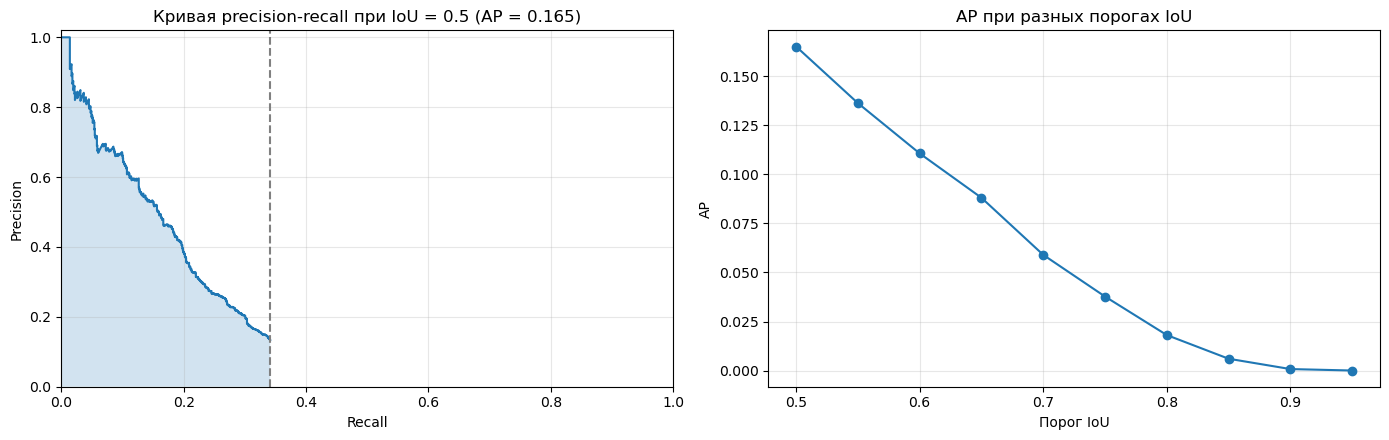

,число эталонных рамок,доля найденных (IoU >= 0.5)
мелкие,482,0.124
средние,482,0.286
крупные,483,0.613


In [15]:
aps = {thr: det_ap(det_preds_test, test_gts, thr) for thr in IOU_THRESHOLDS}
ap_table = pd.DataFrame({'порог IoU': list(aps.keys()), 'AP': list(aps.values())})
display(ap_table.round(4))
det_summary = pd.Series({'AP@0.5': aps[0.5], 'AP@0.75': aps[0.75], 'mAP@0.5:0.95': float(np.mean(list(aps.values())))})
display(det_summary.round(4).to_frame('значение'))
ap_table.to_csv(OUT_DIR / 'detection_ap_by_iou.csv', index=False)
ap05, rec05, prec05 = average_precision(match(det_preds_test, test_gts, 0.5)[1], n_gt)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(rec05, prec05); axes[0].fill_between(rec05, prec05, alpha=0.2)
axes[0].axvline(rec05.max(), color='gray', linestyle='--')
axes[0].set(xlim=(0, 1), ylim=(0, 1.02), xlabel='Recall', ylabel='Precision',
            title=f'Кривая precision-recall при IoU = 0.5 (AP = {ap05:.3f})')
axes[0].grid(alpha=0.3)
axes[1].plot(ap_table['порог IoU'], ap_table['AP'], marker='o')
axes[1].set(xlabel='Порог IoU', ylabel='AP', title='AP при разных порогах IoU'); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

_, tp_all, matched = match(det_preds_test, test_gts, 0.5)
areas = np.array([(b[2] - b[0]) * (b[3] - b[1]) for i in sorted(test_gts) for b in test_gts[i]])
keys = [(i, j) for i in sorted(test_gts) for j in range(len(test_gts[i]))]
terc = pd.qcut(pd.Series(areas).rank(method='first'), 3, labels=['мелкие', 'средние', 'крупные'])
hit = np.array([k in matched for k in keys])
size_det = pd.DataFrame({'число эталонных рамок': pd.Series(terc).value_counts().sort_index(),
                         'доля найденных (IoU >= 0.5)': pd.Series(hit).groupby(terc, observed=True).mean()})
display(size_det.round(3))

#### Как читать результат (AP)

- **Потолок AP.** Кривая precision–recall на графике слева обрывается на recall ≈ 0.34 (пунктир): даже при самых мягких настройках модель находит не больше трети очагов. Площадь под кривой не может быть больше этого значения; измеренный AP@0.5 = 0.165 — примерно половина потолка.
- **Порог IoU.** При IoU = 0.5 AP равен 0.165, при 0.75 — 0.038, mAP@0.5:0.95 = 0.062. То есть часть найденных очагов обведена неточно: рамка модели накрывает очаг, но перекрытие недостаточное.
- **Размер очага.** Крупные эталонные рамки находятся в 61% случаев, средние — в 29%, мелкие — в 12%. Детектор в основном видит крупные очаги, а в тесте их мало: в среднем около 8 рамок на снимок, многие очень мелкие.

**Почему детекция работает хуже сегментации (предположения, их не проверяли).**
- Рамки вычислены из масок; один очаг сложной формы может давать несколько мелких рамок, а соседние очаги — сливаться в одну, и модели трудно угадать именно такую разметку.
- Вход модели 320×320 мал для мелких очагов.
- Обучающих снимков мало (около 600), а модель обучалась 12 эпох на CPU.
- Лучшая эпоха выбрана по validation AP@0.5, а значения на validation после пятой эпохи колеблются в пределах нескольких сотых: дальнейшее обучение не дало заметного улучшения.

## 6. Связь задач и итоги

### Шаг 13. Одни и те же снимки глазами трёх моделей
Для каждого тестового снимка сопоставляются результаты: верно ли определена болезнь, чему равен Dice сегментации, какая доля эталонных рамок найдена (при пороге уверенности `DET_CONF` и IoU = 0.5). Это даёт наблюдение, а не доказательство причинной связи: все три модели работают с одним и тем же снимком, и общая трудность снимка (очаги мелкие, размытый кадр) влияет на все три.

In [16]:
kept = [p for p in det_preds_test if p[1] >= DET_CONF]
_, _, matched_conf = match(kept, test_gts, 0.5)
cross = pd.DataFrame({
    'болезнь': [class_names[c] for c in y_test],
    'класс определён верно': y_test == pred_cls,
    'Dice': seg_df.dice.to_numpy(),
    'pixel accuracy': seg_df.pixel_acc.to_numpy(),
    'доля очага': seg_df.mask_ratio.to_numpy(),
    'эталонных рамок': [len(test_gts[i]) for i in range(len(y_test))],
    'найдено рамок': [sum(1 for j in range(len(test_gts[i])) if (i, j) in matched_conf) for i in range(len(y_test))]})
cross['доля найденных рамок'] = cross['найдено рамок'] / cross['эталонных рамок'].replace(0, np.nan)
cross.to_csv(OUT_DIR / 'cross_task_test.csv', index=False)
display(cross.groupby('класс определён верно')[['Dice', 'pixel accuracy', 'доля очага', 'доля найденных рамок']].agg(['mean', 'count']).round(3))
display(cross.groupby('болезнь').agg(снимков=('Dice', 'size'), accuracy=('класс определён верно', 'mean'), Dice=('Dice', 'mean'),
                                    pixel_accuracy=('pixel accuracy', 'mean'), доля_найденных_рамок=('доля найденных рамок', 'mean')).round(3))
print('Корреляция Спирмена (Dice, доля найденных рамок) по снимкам:',
      round(spearmanr(cross['Dice'], cross['доля найденных рамок'], nan_policy="omit")[0], 3))

Dice       pixel accuracy       доля очага        \
                        mean count           mean count       mean count   
класс определён верно                                                      
False                  0.588    72          0.875    72      0.182    72   
True                   0.658   109          0.900   109      0.170   109   

                      доля найденных рамок        
                                      mean count  
класс определён верно                             
False                                0.283    72  
True                                 0.343   109

,снимков,accuracy,Dice,pixel_accuracy,доля_найденных_рамок
болезнь,,,,,
tomato bacterial leaf spot,22,0.227,0.465,0.836,0.129
tomato early blight,37,0.622,0.624,0.917,0.289
tomato late blight,33,0.697,0.747,0.946,0.638
tomato leaf mold,31,0.774,0.658,0.910,0.368
tomato mosaic virus,13,0.231,0.596,0.804,0.254
tomato septoria leaf spot,26,0.577,0.665,0.874,0.260
tomato yellow leaf curl virus,19,0.842,0.563,0.853,0.090


Корреляция Спирмена (Dice, доля найденных рамок) по снимкам: 0.587


#### Как читать результат (связь задач)

- На снимках, где болезнь определена верно, средний Dice выше (0.66 против 0.59) и находится больше рамок (0.34 против 0.28). Размер очага у двух групп почти одинаков (0.17 и 0.18), поэтому разницу размером не объяснить. Возможная общая причина — качество самого снимка, но это не проверялось, и числа получены на небольших группах (72 и 109 снимков) без интервалов.
- Dice и доля найденных рамок согласованы (корреляция около 0.59): там, где сегментация удалась, и рамки находятся лучше.
- Классы заметно различаются: у late blight лучшие Dice и доля найденных рамок, у yellow leaf curl virus классификация лучшая, а рамки почти не находятся (доля 0.09). Предположение: симптом этой болезни — скручивание листа без отдельных очагов, поэтому рамки из маски плохо описывают его. Это гипотеза, она не проверялась.

### Шаг 14. Итоговая сводка
Одна таблица главных чисел по всем задачам. Сравнивать значения между строками разных задач не нужно: у них разные способы расчёта и разные эталоны. Ценность таблицы в том, что для каждой метрики рядом показано, чем она отличается от соседней.

In [17]:
final = pd.DataFrame([
    ['Классификация', 'accuracy', accuracy_score(y_test, pred_cls)],
    ['Классификация', 'macro-F1', f_.mean()],
    ['Классификация', 'ROC-AUC (среднее по болезням)', ovr['ROC-AUC'].mean()],
    ['Сегментация', 'Dice (среднее по снимкам)', seg_df.dice.mean()],
    ['Сегментация', 'Dice (по всем пикселям)', summary.loc['dice', 'по всем пикселям']],
    ['Сегментация', 'IoU (среднее по снимкам)', seg_df.iou.mean()],
    ['Сегментация', 'pixel accuracy (пустая маска даёт %.3f)' % empty_baseline, seg_df.pixel_acc.mean()],
    ['Детекция', 'AP@0.5', det_summary['AP@0.5']],
    ['Детекция', 'AP@0.75', det_summary['AP@0.75']],
    ['Детекция', 'mAP@0.5:0.95', det_summary['mAP@0.5:0.95']]], columns=['задача', 'метрика', 'значение'])
display(final.round(4))
final.to_csv(OUT_DIR / 'final_summary.csv', index=False)
(OUT_DIR / 'run_info.json').write_text(json.dumps({k: {kk: vv for kk, vv in v.items() if kk != 'curve'} for k, v in INFO.items()},
                                                  ensure_ascii=False, indent=2, default=str), encoding='utf-8')

,задача,метрика,значение
0,Классификация,accuracy,0.6022
1,Классификация,macro-F1,0.5537
2,Классификация,ROC-AUC (среднее по болезням),0.9177
3,Сегментация,Dice (среднее по снимкам),0.6304
4,Сегментация,Dice (по всем пикселям),0.6835
5,Сегментация,IoU (среднее по снимкам),0.4972
6,Сегментация,pixel accuracy (пустая маска даёт 0.825),0.8901
7,Детекция,AP@0.5,0.1651
8,Детекция,AP@0.75,0.0377
9,Детекция,mAP@0.5:0.95,0.0622


247

### Итоговые выводы

1. **Accuracy скрывает слабые классы.** Accuracy 0.60 при macro-F1 0.55 и F1 по отдельным болезням от 0.27 до 0.74. Для задачи, где нельзя пропускать болезнь, нужны recall и F1 по классам.
2. **Одно число отвечает на один вопрос.** Accuracy проверяет окончательный диагноз, ROC-AUC и AP — качество вероятностей болезни по отдельности. Поэтому при AUC 0.92 accuracy может быть 0.60, и это не противоречие.
3. **Метрику нужно сравнивать с тривиальным ответом.** Пустая маска даёт pixel accuracy 0.825, а модель — 0.890; Dice пустой маски равен 0. Поэтому для сегментации малых объектов основной метрикой служат Dice или IoU.
4. **Способ усреднения меняет число.** Macro и weighted для классификации; среднее по снимкам и по пикселям для сегментации (Dice 0.63 и 0.68). Всегда указывайте, как усреднено.
5. **В детекции результат задают два порога.** Порог уверенности выбирает рабочую точку precision и recall; AP от него не зависит. Порог IoU задаёт строгость к рамке: AP@0.5 = 0.165, AP@0.75 = 0.038. AP не может быть больше максимальной достигнутой полноты (здесь 0.34).
6. **Малый тест ограничивает выводы.** Интервал accuracy при 181 снимке около ±7 п.п.; различия моделей меньше этого значения неразличимы.

### Ограничения работы
- Модели простые и не настраивались; значения качества не характеризуют потолок задачи.
- Рамки получены из масок, независимой ручной разметки рамок нет.
- Один запуск и одно разбиение; интервалы для сегментации и детекции не считались.
- Часть объяснений причин (слияние рамок, диффузные симптомы, влияние качества снимка) — предположения, они не проверялись экспериментально.
- Экспериментов с принудительным изменением условий (изменение доли класса, сдвиг маски) в работе нет: она анализирует метрики на одном наборе ответов моделей.

## Вопросы для отчёта

1. Классификация: какие классы путаются чаще всего? Совпадает ли ранжирование классов по F1, по ROC-AUC и по AP? Что показывают интервалы бутстрепа при таком объёме теста?
2. Сегментация: чем отличаются метрики «среднее по снимкам» и «по всем пикселям»? Как Dice, IoU и pixel accuracy зависят от доли очага? Почему pixel accuracy высока при невысоком Dice?
3. Детекция: как изменяется AP при росте порога IoU? Как порог уверенности меняет Precision, Recall и F1? Какие рамки по размеру находятся хуже?
4. Связь задач: отличается ли качество сегментации у верно и неверно классифицированных снимков? Для каких классов сегментация и детекция лучше?
5. Какая из метрик, по вашему мнению, лучше всего описывает качество решения прикладной задачи (поиск очагов на листе)? Обоснуйте.
6. Ограничения: небольшой объём данных, рамки получены из масок, разрешение снижено до `IMG_SIZE`, модели не настраивались подробно.

In [1]:
# Установка зависимостей (один раз)
!pip install -q kagglehub torch torchvision scikit-learn scipy matplotlib pillow pandas

  You can safely remove it manually.
  You can safely remove it manually.

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
from pathlib import Path
import shutil, kagglehub

ROOT = Path('./plantsegv2')

def deploy_plantseg(src_dir: Path, dst: Path = ROOT) -> None:
    """Копирует PlantSeg v2 в dst, находя каталог с Metadatav2.csv внутри src_dir."""
    meta_files = list(src_dir.rglob('Metadatav2.csv'))
    if not meta_files:
        raise FileNotFoundError(
            f'Metadatav2.csv не найден внутри {src_dir}. '
            'Проверьте, что скачался именно PlantSeg v2 (внутри должна быть папка plantsegv2).'
        )
    base = meta_files[0].parent
    # В разных копиях датасета структура может быть «plantsegv2/...» или сразу «.../Metadatav2.csv»
    if base.name.lower() == 'plantsegv2':
        src_root = base
    else:
        src_root = base if (base / 'images').exists() else base / 'plantsegv2'
    if not (src_root / 'images').exists() or not (src_root / 'annotations').exists():
        raise FileNotFoundError(
            f'В {src_root} нет папок images/ и annotations/. '
            'Скорее всего, скачан не тот датасет или архив неполный.'
        )
    if dst.exists():
        shutil.rmtree(dst)
    shutil.copytree(src_root, dst)
    print(f'PlantSeg v2 развёрнут в {dst.resolve()}')

if not (ROOT / 'Metadatav2.csv').exists():
    # --- Вариант 1: Kaggle через kagglehub (owner/dataset-name) ---
    KAGGLE_SLUG = 'weitianqi/plantseg'   # правильный полный идентификатор
    try:
        print(f'Скачиваем {KAGGLE_SLUG} через Kaggle...')
        cache_path = Path(kagglehub.dataset_download(KAGGLE_SLUG))
        deploy_plantseg(cache_path)
    except Exception as e:
        print(f'Kaggle не сработал: {e}')
        print('\nРезервный вариант — Zenodo (официальная полная версия PlantSeg):')
        print('https://zenodo.org/records/13958858')
        print('Скачайте архив вручную, распакуйте и положите папку plantsegv2 рядом с ноутбуком,')
        print('либо укажите путь к ней в переменной ROOT и перезапустите ячейку.')
        raise
else:
    print(f'Датасет уже есть: {ROOT.resolve()}')

# Проверка структуры
assert (ROOT / 'Metadatav2.csv').exists()
assert (ROOT / 'images').exists()
assert (ROOT / 'annotations').exists()
print('Структура корректна:', sorted(p.name for p in ROOT.iterdir()))

C:\Users\Svetozar\PycharmProjects\NTMIP\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Скачиваем weitianqi/plantseg через Kaggle...


100%|██████████| 1.59G/1.59G [09:15<00:00, 3.08MB/s]

Extracting files...


PlantSeg v2 развёрнут в C:\Users\Svetozar\PycharmProjects\NTMIP\lab_9\plantsegv2
Структура корректна: ['Metadatav2.csv', 'annotations', 'coco_annotations.json', 'images']


In [1]:
from pathlib import Path
import copy, json, pickle, platform, random, time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from IPython.display import display
from scipy.ndimage import label as cc_label, find_objects
from scipy.stats import spearmanr
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, average_precision_score)

ROOT = Path('./plantsegv2')
META = ROOT / 'Metadatav2.csv'
PLANT = 'Tomato'
OUT_DIR = Path('./results_lab09_plantseg')
OUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE = OUT_DIR / 'predictions.pkl'
RETRAIN = False
SEED = 42
IMG_SIZE = 320
MIN_BOX_FRAC = 0.0005
EPOCHS_CLS, EPOCHS_SEG, EPOCHS_DET = 30, 15, 12
BATCH_SEG, BATCH_DET = 8, 4
DET_CONF = 0.5

need_train = RETRAIN or not CACHE.exists()
print('Режим:', 'обучение' if need_train else f'загрузка из {CACHE}')

Режим: обучение


In [2]:
meta = pd.read_csv(META)
meta = meta[meta.Plant.astype(str).str.strip().str.lower() == PLANT.lower()].copy()

def index_files(folder):
    d = {}
    for p in folder.rglob('*'):
        if p.is_file():
            d.setdefault(p.name, p); d.setdefault(p.stem, p)
    return d

img_idx, mask_idx = index_files(ROOT / 'images'), index_files(ROOT / 'annotations')
def find(idx, name):
    n = Path(str(name)).name
    return idx.get(n) or idx.get(Path(n).stem)

meta['img_path']  = meta['Name'].map(lambda n: find(img_idx, n))
meta['mask_path'] = meta['Label file'].map(lambda n: find(mask_idx, n))
meta = meta[meta.img_path.notna() & meta.mask_path.notna()].copy().reset_index(drop=True)
meta['split'] = meta['Split'].astype(str).str.strip().str.lower().map(
    {'training':'train','validation':'val','test':'test'})
assert meta.split.notna().all(), meta['Split'].unique()

class_names = sorted(meta['Disease'].unique())
K = len(class_names)
meta['label'] = meta['Disease'].map({c:i for i,c in enumerate(class_names)})
all_ids = np.arange(K)
display(pd.crosstab(meta['Disease'], meta.split).reindex(columns=['train','val','test'], fill_value=0))
print('Всего:', len(meta), '| классов:', K)

split,train,val,test
Disease,,,
tomato bacterial leaf spot,75,12,22
tomato early blight,130,20,37
tomato late blight,113,17,33
tomato leaf mold,108,17,31
tomato mosaic virus,43,7,13
tomato septoria leaf spot,90,14,26
tomato yellow leaf curl virus,64,10,19


Всего: 901 | классов: 7


In [3]:
S = IMG_SIZE

def load_sample(img_path, mask_path):
    im = Image.open(img_path).convert('RGB').resize((S, S), Image.BILINEAR)
    m = np.array(Image.open(mask_path))
    if m.ndim == 3: m = m[..., 0]
    m = np.array(Image.fromarray((m > 0).astype('uint8')).resize((S, S), Image.NEAREST)).astype(bool)
    return np.array(im), m

def mask_to_boxes(mask):
    lab, n = cc_label(mask)
    boxes = []
    for i, sl in enumerate(find_objects(lab), 1):
        if sl is None: continue
        area = int((lab[sl] == i).sum())
        if area >= MIN_BOX_FRAC * S * S:
            boxes.append((sl[1].start, sl[0].start, sl[1].stop, sl[0].stop))
    return np.array(boxes, dtype=np.float32).reshape(-1, 4)

t0 = time.perf_counter()
data = {}
for split in (['train','val','test'] if need_train else ['test']):
    sub = meta[meta.split == split].reset_index(drop=True)
    ims, mks, bxs = [], [], []
    for r in sub.itertuples():
        im, mk = load_sample(r.img_path, r.mask_path)
        ims.append(im); mks.append(mk); bxs.append(mask_to_boxes(mk))
    data[split] = {'meta': sub, 'images': np.stack(ims), 'masks': np.stack(mks),
                   'boxes': bxs, 'labels': sub.label.to_numpy()}
print(f'Загрузка: {time.perf_counter()-t0:.1f} с')
display(pd.DataFrame({s: {'снимков': len(d['labels']),
                          'доля очага': d['masks'].mean(),
                          'рамок/снимок': np.mean([len(b) for b in d['boxes']])}
                      for s,d in data.items()}).T.round(3))

Загрузка: 32.0 с


,снимков,доля очага,рамок/снимок
train,623.0,0.173,7.737
val,97.0,0.173,7.825
test,181.0,0.175,7.994


In [4]:
IOU_THRESHOLDS = np.round(np.arange(0.5, 0.96, 0.05), 2)

def iou_box(a, b):
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter/union if union > 0 else 0.0

def match(preds, gts, thr):
    order = sorted(preds, key=lambda p: -p[1])
    used = {i: np.zeros(len(b), bool) for i,b in gts.items()}
    scores, tp, matched = [], [], set()
    for img, score, box in order:
        best, best_j = 0.0, -1
        for j, g in enumerate(gts.get(img, [])):
            if used[img][j]: continue
            v = iou_box(box, g)
            if v > best: best, best_j = v, j
        hit = best >= thr
        if hit: used[img][best_j] = True; matched.add((img, best_j))
        scores.append(score); tp.append(1.0 if hit else 0.0)
    return np.array(scores), np.array(tp), matched

def average_precision(tp, n_gt):
    if len(tp) == 0 or n_gt == 0:
        return 0.0, np.array([0.0]), np.array([1.0])
    ctp, cfp = np.cumsum(tp), np.cumsum(1-tp)
    rec, prec = ctp/n_gt, ctp/(ctp+cfp)
    mrec, mpre = np.r_[0.0, rec, 1.0], np.r_[0.0, prec, 0.0]
    for i in range(len(mpre)-2, -1, -1):
        mpre[i] = max(mpre[i], mpre[i+1])
    idx = np.flatnonzero(mrec[1:] != mrec[:-1])
    return float(np.sum((mrec[idx+1]-mrec[idx])*mpre[idx+1])), rec, prec

def det_ap(preds, gts, thr):
    n_gt = sum(len(b) for b in gts.values())
    _, tp, _ = match(preds, gts, thr)
    return average_precision(tp, n_gt)[0]

def seg_metrics(gt, pr):
    tp = int((gt & pr).sum()); fp = int((~gt & pr).sum())
    fn = int((gt & ~pr).sum()); tn = int((~gt & ~pr).sum())
    empty = tp+fp+fn == 0
    return {'tp':tp,'fp':fp,'fn':fn,'tn':tn,
            'dice': 1.0 if empty else 2*tp/(2*tp+fp+fn),
            'iou':  1.0 if empty else tp/(tp+fp+fn),
            'pixel_acc': (tp+tn)/gt.size,
            'precision': tp/max(tp+fp,1), 'recall': tp/max(tp+fn,1)}

assert abs(iou_box((0,0,10,10),(5,0,15,10)) - 1/3) < 1e-9
print('Метрики готовы')

Метрики готовы


In [6]:
def train_classifier():
    import torch
    from torch import nn
    import torch.nn.functional as F
    from torchvision import models
    dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    mean_t = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
    std_t = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
    def to_input(b):
        return (torch.from_numpy(b).permute(0, 3, 1, 2).float() / 255.0 - mean_t) / std_t
    t_all = time.perf_counter()
    torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
    bb = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    bb.fc = nn.Identity(); bb.requires_grad_(False); bb = bb.to(dev).eval()
    feats = {}
    with torch.inference_mode():
        for s in ['train', 'val', 'test']:
            arr = data[s]['images']
            feats[s] = torch.cat([bb(to_input(arr[i:i+32]).to(dev)).cpu() for i in range(0, len(arr), 32)])
    t_feat = time.perf_counter() - t_all
    def probs(h, x):
        h.eval()
        with torch.no_grad():
            return h(x.to(dev)).softmax(1).cpu().numpy()
    head = nn.Linear(feats['train'].shape[1], K).to(dev)
    opt = torch.optim.Adam(head.parameters(), lr=1e-3)
    y_tr = torch.from_numpy(data['train']['labels']).long()
    best, best_state, best_epoch, curve = -1.0, None, 0, []
    for epoch in range(1, EPOCHS_CLS + 1):
        head.train()
        perm = torch.randperm(len(y_tr))
        for i in range(0, len(perm), 64):
            b = perm[i:i+64]
            opt.zero_grad()
            F.cross_entropy(head(feats['train'][b].to(dev)), y_tr[b].to(dev)).backward()
            opt.step()
        sc = f1_score(data['val']['labels'], probs(head, feats['val']).argmax(1),
                      labels=all_ids, average='macro', zero_division=0)
        curve.append(float(sc))
        if sc > best:
            best, best_epoch, best_state = sc, epoch, copy.deepcopy(head.state_dict())
    head.load_state_dict(best_state)
    info = {'best_epoch': best_epoch, 'best_val': round(float(best), 4), 'curve': curve,
            'seconds': round(time.perf_counter() - t_all, 1),
            'seconds_features': round(t_feat, 1),
            'params': int(sum(p.numel() for p in head.parameters()) + sum(p.numel() for p in bb.parameters()))}
    print(f'Классификация: лучшая эпоха {best_epoch}, validation macro-F1 = {best:.4f}')
    return probs(head, feats['test']), info


def train_segmentation():
    import torch
    from torch import nn
    import torch.nn.functional as F
    from torchvision.models.segmentation import lraspp_mobilenet_v3_large, LRASPP_MobileNet_V3_Large_Weights
    dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    mean_t = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
    std_t = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
    def to_input(b):
        return (torch.from_numpy(b).permute(0, 3, 1, 2).float() / 255.0 - mean_t) / std_t
    torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
    m = lraspp_mobilenet_v3_large(weights=LRASPP_MobileNet_V3_Large_Weights.COCO_WITH_VOC_LABELS_V1)
    m.classifier.low_classifier = nn.Conv2d(m.classifier.low_classifier.in_channels, 2, 1)
    m.classifier.high_classifier = nn.Conv2d(m.classifier.high_classifier.in_channels, 2, 1)
    m = m.to(dev)
    def loss_fn(logits, target):
        ce = F.cross_entropy(logits, target)
        p, t = logits.softmax(1)[:, 1], target.float()
        inter = (p * t).sum((1, 2))
        return ce + (1 - (2 * inter + 1) / (p.sum((1, 2)) + t.sum((1, 2)) + 1)).mean()
    def predict(images, bs=16):
        m.eval(); out = []
        with torch.inference_mode():
            for i in range(0, len(images), bs):
                out.append((m(to_input(images[i:i+bs]).to(dev))['out'].argmax(1) == 1).cpu().numpy())
        return np.concatenate(out)
    def mean_dice(pred, gt):
        return float(np.mean([seg_metrics(g, p)['dice'] for g, p in zip(gt, pred)]))
    opt = torch.optim.AdamW(m.parameters(), lr=3e-4)
    n_tr = len(data['train']['labels'])
    t_all = time.perf_counter()
    best, best_state, best_epoch, curve, secs = -1.0, None, 0, [], []
    for epoch in range(1, EPOCHS_SEG + 1):
        te = time.perf_counter(); m.train()
        perm = np.random.permutation(n_tr)
        for i in range(0, n_tr, BATCH_SEG):
            b = np.sort(perm[i:i+BATCH_SEG])
            if len(b) < 2: continue
            x = to_input(data['train']['images'][b]).to(dev)
            y = torch.from_numpy(data['train']['masks'][b].astype(np.int64)).to(dev)
            if random.random() < 0.5:
                x, y = x.flip(-1), y.flip(-1)
            opt.zero_grad(); loss_fn(m(x)['out'], y).backward(); opt.step()
        d = mean_dice(predict(data['val']['images']), data['val']['masks'])
        curve.append(round(d, 4)); secs.append(round(time.perf_counter() - te, 1))
        print(f'Сегментация, эпоха {epoch}/{EPOCHS_SEG}: validation Dice = {d:.4f}')
        if d > best:
            best, best_epoch, best_state = d, epoch, copy.deepcopy(m.state_dict())
    m.load_state_dict(best_state)
    t_tot = time.perf_counter() - t_all
    t0 = time.perf_counter(); pred = predict(data['test']['images']); t_inf = time.perf_counter() - t0
    info = {'best_epoch': best_epoch, 'best_val': round(float(best), 4), 'curve': curve,
            'epoch_seconds': secs, 'seconds': round(t_tot, 1),
            'inference_ms_per_image': round(1000 * t_inf / len(pred), 1),
            'params': int(sum(p.numel() for p in m.parameters()))}
    return pred, info


def train_detection():
    import torch
    from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_320_fpn, FasterRCNN_MobileNet_V3_Large_320_FPN_Weights
    from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
    dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
    m = fasterrcnn_mobilenet_v3_large_320_fpn(weights=FasterRCNN_MobileNet_V3_Large_320_FPN_Weights.COCO_V1)
    m.roi_heads.box_predictor = FastRCNNPredictor(m.roi_heads.box_predictor.cls_score.in_features, 2)
    m = m.to(dev)
    def tens(a):
        return torch.from_numpy(a).permute(2, 0, 1).float() / 255.0
    def predict(images, bs=8):
        m.eval(); preds = []
        with torch.inference_mode():
            for i in range(0, len(images), bs):
                outs = m([tens(a).to(dev) for a in images[i:i+bs]])
                for j, o in enumerate(outs):
                    for box, sc in zip(o['boxes'].cpu().numpy(), o['scores'].cpu().numpy()):
                        preds.append((i + j, float(sc), tuple(float(v) for v in box)))
        return preds
    val_gts = {i: b for i, b in enumerate(data['val']['boxes'])}
    train_ids = [i for i, b in enumerate(data['train']['boxes']) if len(b) > 0]
    opt = torch.optim.SGD([p for p in m.parameters() if p.requires_grad],
                          lr=0.005, momentum=0.9, weight_decay=5e-4)
    t_all = time.perf_counter()
    best, best_state, best_epoch, curve, secs = -1.0, None, 0, [], []
    for epoch in range(1, EPOCHS_DET + 1):
        te = time.perf_counter(); m.train()
        perm = np.random.permutation(train_ids)
        for i in range(0, len(perm), BATCH_DET):
            imgs, tgts = [], []
            for k in perm[i:i+BATCH_DET]:
                im = tens(data['train']['images'][k])
                bx = torch.from_numpy(data['train']['boxes'][k]).clone()
                if random.random() < 0.5:
                    im = im.flip(-1); bx[:, [0, 2]] = S - bx[:, [2, 0]]
                imgs.append(im.to(dev))
                tgts.append({'boxes': bx.to(dev),
                             'labels': torch.ones(len(bx), dtype=torch.int64, device=dev)})
            opt.zero_grad(); sum(m(imgs, tgts).values()).backward(); opt.step()
        ap = det_ap(predict(data['val']['images']), val_gts, 0.5)
        curve.append(round(ap, 4)); secs.append(round(time.perf_counter() - te, 1))
        print(f'Детекция, эпоха {epoch}/{EPOCHS_DET}: validation AP@0.5 = {ap:.4f}')
        if ap > best:
            best, best_epoch, best_state = ap, epoch, copy.deepcopy(m.state_dict())
    m.load_state_dict(best_state)
    t_tot = time.perf_counter() - t_all
    t0 = time.perf_counter(); preds = predict(data['test']['images']); t_inf = time.perf_counter() - t0
    info = {'best_epoch': best_epoch, 'best_val': round(float(best), 4), 'curve': curve,
            'epoch_seconds': secs, 'seconds': round(t_tot, 1),
            'inference_ms_per_image': round(1000 * t_inf / len(data['test']['labels']), 1),
            'params': int(sum(p.numel() for p in m.parameters()))}
    return preds, info

print('Функции обучения определены')

Функции обучения определены


In [7]:
for name in ['train_classifier', 'train_segmentation', 'train_detection']:
    print(name, '->', 'определено' if name in globals() else 'НЕ ОПРЕДЕЛЕНО')

train_classifier -> определено
train_segmentation -> определено
train_detection -> определено


In [8]:
for name in ['need_train','CACHE','data','class_names','train_classifier',
             'train_segmentation','train_detection','prob_test']:
    print(name, '->', 'определено' if name in globals() else 'НЕ ОПРЕДЕЛЕНО')

need_train -> определено
CACHE -> определено
data -> определено
class_names -> определено
train_classifier -> определено
train_segmentation -> определено
train_detection -> определено
prob_test -> НЕ ОПРЕДЕЛЕНО


In [26]:
!pip install "numpy<2"


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
import torch
print('CUDA available:', torch.cuda.is_available())
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'N/A')

CUDA available: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


In [10]:
if need_train:
    prob_test,        info_cls = train_classifier()
    pred_masks_test,  info_seg = train_segmentation()
    det_preds_test,   info_det = train_detection()
    INFO = {'cls': info_cls, 'seg': info_seg, 'det': info_det}
    with open(CACHE, 'wb') as f:
        pickle.dump({'prob_test': prob_test,
                     'pred_masks_test': pred_masks_test,
                     'det_preds_test': det_preds_test,
                     'classes': class_names,
                     'test_names': data['test']['meta']['Name'].tolist(),
                     'info': INFO}, f)
    print('Сохранено в', CACHE)

Классификация: лучшая эпоха 14, validation macro-F1 = 0.6119


Downloading: "https://download.pytorch.org/models/lraspp_mobilenet_v3_large-d234d4ea.pth" to C:\Users\Svetozar/.cache\torch\hub\checkpoints\lraspp_mobilenet_v3_large-d234d4ea.pth
100%|██████████| 12.5M/12.5M [00:01<00:00, 10.2MB/s]


Сегментация, эпоха 1/15: validation Dice = 0.5318
Сегментация, эпоха 2/15: validation Dice = 0.5930
Сегментация, эпоха 3/15: validation Dice = 0.5999
Сегментация, эпоха 4/15: validation Dice = 0.6173
Сегментация, эпоха 5/15: validation Dice = 0.6255
Сегментация, эпоха 6/15: validation Dice = 0.6434
Сегментация, эпоха 7/15: validation Dice = 0.5967
Сегментация, эпоха 8/15: validation Dice = 0.6165
Сегментация, эпоха 9/15: validation Dice = 0.6339
Сегментация, эпоха 10/15: validation Dice = 0.6381
Сегментация, эпоха 11/15: validation Dice = 0.6325
Сегментация, эпоха 12/15: validation Dice = 0.6202
Сегментация, эпоха 13/15: validation Dice = 0.6393
Сегментация, эпоха 14/15: validation Dice = 0.6506
Сегментация, эпоха 15/15: validation Dice = 0.6326


Downloading: "https://download.pytorch.org/models/fasterrcnn_mobilenet_v3_large_320_fpn-907ea3f9.pth" to C:\Users\Svetozar/.cache\torch\hub\checkpoints\fasterrcnn_mobilenet_v3_large_320_fpn-907ea3f9.pth
100%|██████████| 74.2M/74.2M [00:07<00:00, 11.1MB/s]


Детекция, эпоха 1/12: validation AP@0.5 = 0.1308
Детекция, эпоха 2/12: validation AP@0.5 = 0.1464
Детекция, эпоха 3/12: validation AP@0.5 = 0.1486
Детекция, эпоха 4/12: validation AP@0.5 = 0.1700
Детекция, эпоха 5/12: validation AP@0.5 = 0.1777
Детекция, эпоха 6/12: validation AP@0.5 = 0.1688
Детекция, эпоха 7/12: validation AP@0.5 = 0.1692
Детекция, эпоха 8/12: validation AP@0.5 = 0.1706
Детекция, эпоха 9/12: validation AP@0.5 = 0.1617
Детекция, эпоха 10/12: validation AP@0.5 = 0.1600
Детекция, эпоха 11/12: validation AP@0.5 = 0.1530
Детекция, эпоха 12/12: validation AP@0.5 = 0.1502
Сохранено в results_lab09_plantseg\predictions.pkl


,снимков,названо,TP,FN,FP,precision,recall,F1
tomato bacterial leaf spot,22,8,4,18,4,0.500,0.182,0.267
tomato early blight,37,36,24,13,12,0.667,0.649,0.658
tomato late blight,33,30,20,13,10,0.667,0.606,0.635
tomato leaf mold,31,46,26,5,20,0.565,0.839,0.675
tomato mosaic virus,13,9,4,9,5,0.444,0.308,0.364
tomato septoria leaf spot,26,30,15,11,15,0.500,0.577,0.536
tomato yellow leaf curl virus,19,22,15,4,7,0.682,0.789,0.732


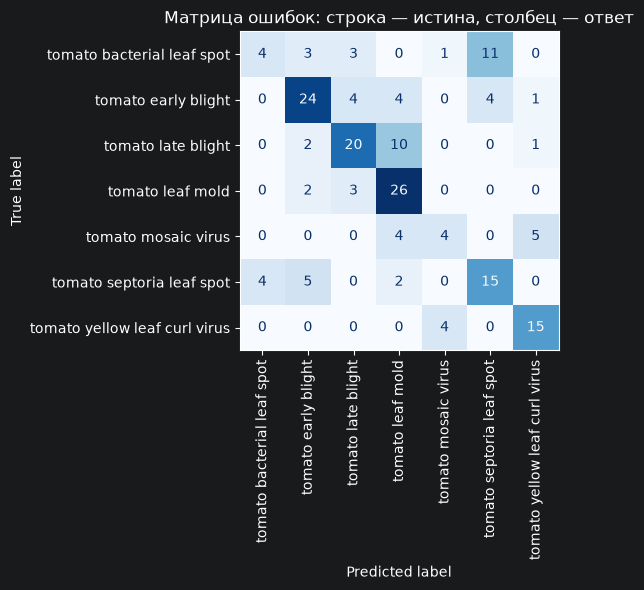

accuracy             0.5967
balanced accuracy    0.5642
macro-F1             0.5522
weighted-F1          0.5781
dtype: float64


In [11]:
y_test    = data['test']['labels']
pred_cls  = prob_test.argmax(1)
cm        = confusion_matrix(y_test, pred_cls, labels=all_ids)
tp_c, fn_c, fp_c = np.diag(cm), cm.sum(1)-np.diag(cm), cm.sum(0)-np.diag(cm)

counts = pd.DataFrame({
    'снимков': cm.sum(1), 'названо': cm.sum(0),
    'TP':tp_c, 'FN':fn_c, 'FP':fp_c,
    'precision': tp_c/np.maximum(tp_c+fp_c,1),
    'recall':    tp_c/np.maximum(tp_c+fn_c,1)}, index=class_names)
counts['F1'] = 2*counts.precision*counts.recall/np.maximum(counts.precision+counts.recall,1e-9)
display(counts.round(3))

fig, ax = plt.subplots(figsize=(7,6))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, cmap='Blues', xticks_rotation=90, colorbar=False)
ax.set_title('Матрица ошибок: строка — истина, столбец — ответ')
plt.tight_layout(); plt.show()

p_, r_, f_, _ = precision_recall_fscore_support(y_test, pred_cls, labels=all_ids, zero_division=0)
_, _, fw_, _  = precision_recall_fscore_support(y_test, pred_cls, labels=all_ids,
                                                average='weighted', zero_division=0)
print(pd.Series({'accuracy': accuracy_score(y_test, pred_cls),
                 'balanced accuracy': r_.mean(),
                 'macro-F1': f_.mean(),
                 'weighted-F1': fw_}).round(4))
counts.to_csv(OUT_DIR / 'classification_by_class.csv')

In [12]:
ovr = pd.DataFrame({
    'снимков':  [int((y_test==c).sum()) for c in all_ids],
    'доля':     [float((y_test==c).mean()) for c in all_ids],
    'ROC-AUC':  [roc_auc_score((y_test==c).astype(int), prob_test[:,c]) for c in all_ids],
    'AP':       [average_precision_score((y_test==c).astype(int), prob_test[:,c]) for c in all_ids]
}, index=class_names)
ovr['AP/доля'] = ovr['AP']/ovr['доля']
display(ovr.round(3))
print(f"ROC-AUC (среднее): {ovr['ROC-AUC'].mean():.3f}")

rng = np.random.default_rng(SEED)
bs = []
for _ in range(1000):
    i = rng.integers(0, len(y_test), len(y_test))
    _, _, f, _ = precision_recall_fscore_support(y_test[i], pred_cls[i], labels=all_ids, zero_division=0)
    bs.append([accuracy_score(y_test[i], pred_cls[i]), f.mean()])
lo, hi = np.percentile(np.array(bs), [2.5, 97.5], axis=0)
print(f'accuracy = {accuracy_score(y_test, pred_cls):.3f}, 95% ДИ [{lo[0]:.3f}; {hi[0]:.3f}]')
print(f'macro-F1 = {f_.mean():.3f}, 95% ДИ [{lo[1]:.3f}; {hi[1]:.3f}]')
ovr.to_csv(OUT_DIR / 'classification_ovr.csv')

,снимков,доля,ROC-AUC,AP,AP/доля
tomato bacterial leaf spot,22,0.122,0.904,0.520,4.275
tomato early blight,37,0.204,0.906,0.733,3.585
tomato late blight,33,0.182,0.907,0.682,3.742
tomato leaf mold,31,0.171,0.918,0.731,4.270
tomato mosaic virus,13,0.072,0.882,0.345,4.803
tomato septoria leaf spot,26,0.144,0.877,0.582,4.050
tomato yellow leaf curl virus,19,0.105,0.967,0.716,6.823


ROC-AUC (среднее): 0.909
accuracy = 0.597, 95% ДИ [0.525; 0.669]
macro-F1 = 0.552, 95% ДИ [0.470; 0.626]


In [13]:
gt_masks_test = data['test']['masks']
rows = []
for gt, pr in zip(gt_masks_test, pred_masks_test):
    m = seg_metrics(gt, pr); m['mask_ratio'] = gt.mean(); rows.append(m)
seg_df = pd.DataFrame(rows)
tp, fp, fn, tn = (seg_df[c].sum() for c in ['tp','fp','fn','tn'])

summary = pd.DataFrame({
    'среднее по снимкам': seg_df[['dice','iou','pixel_acc','precision','recall']].mean(),
    'по всем пикселям':  pd.Series({
        'dice': 2*tp/(2*tp+fp+fn), 'iou': tp/(tp+fp+fn),
        'pixel_acc': (tp+tn)/(tp+tn+fp+fn),
        'precision': tp/max(tp+fp,1), 'recall': tp/max(tp+fn,1)})})
display(summary.round(4))

empty_baseline = 1 - gt_masks_test.mean()
print(f'Пустая маска: pixel accuracy = {empty_baseline:.3f}, Dice = 0')
D = summary.loc['dice','по всем пикселям']
print(f'IoU = D/(2−D): {D:.4f} -> {D/(2-D):.4f} (измерено {summary.loc["iou","по всем пикселям"]:.4f})')
summary.to_csv(OUT_DIR / 'segmentation_summary.csv')

,среднее по снимкам,по всем пикселям
dice,0.6332,0.6838
iou,0.5003,0.5195
pixel_acc,0.8931,0.8931
precision,0.6673,0.7074
recall,0.6755,0.6616


Пустая маска: pixel accuracy = 0.825, Dice = 0
IoU = D/(2−D): 0.6838 -> 0.5195 (измерено 0.5195)


In [14]:
seg_df['q'] = pd.qcut(seg_df['mask_ratio'], 4, labels=['Q1 (мелкие)','Q2','Q3','Q4 (крупные)'])
by_size = seg_df.groupby('q', observed=True).agg(
    доля_очага=('mask_ratio','mean'), Dice=('dice','mean'), IoU=('iou','mean'),
    pixel_acc=('pixel_acc','mean'), precision=('precision','mean'), recall=('recall','mean')).round(3)
display(by_size)
print('Спирмен (доля_очага, Dice)      =', round(spearmanr(seg_df['mask_ratio'], seg_df['dice'])[0], 3))
print('Спирмен (доля_очага, pixel_acc) =', round(spearmanr(seg_df['mask_ratio'], seg_df['pixel_acc'])[0], 3))
by_size.to_csv(OUT_DIR / 'segmentation_by_size.csv')

,доля_очага,Dice,IoU,pixel_acc,precision,recall
q,,,,,,
Q1 (мелкие),0.039,0.535,0.407,0.954,0.515,0.660
Q2,0.097,0.639,0.500,0.918,0.618,0.712
Q3,0.178,0.672,0.533,0.889,0.715,0.685
Q4 (крупные),0.389,0.689,0.563,0.810,0.824,0.646


Спирмен (доля_очага, Dice)      = 0.269
Спирмен (доля_очага, pixel_acc) = -0.637


In [15]:
test_gts = {i:b for i,b in enumerate(data['test']['boxes'])}
n_gt     = sum(len(b) for b in test_gts.values())

rows = []
for conf in [0.05, 0.20, 0.35, 0.50, 0.65, 0.80]:
    kept = [p for p in det_preds_test if p[1] >= conf]
    _, tp_, _ = match(kept, test_gts, 0.5)
    TP = int(tp_.sum()); FP = len(kept)-TP; FN = n_gt-TP
    rows.append({'conf': conf, 'оставлено': len(kept), 'TP':TP, 'FP':FP, 'FN':FN,
                 'precision': TP/max(TP+FP,1), 'recall': TP/max(n_gt,1),
                 'F1': 2*TP/max(2*TP+FP+FN,1)})
conf_table = pd.DataFrame(rows).round(3)
print('Эталонных рамок в тесте:', n_gt)
display(conf_table)
conf_table.to_csv(OUT_DIR / 'detection_confidence_thresholds.csv', index=False)

Эталонных рамок в тесте: 1447


,conf,оставлено,TP,FP,FN,precision,recall,F1
0,0.05,3628,484,3144,963,0.133,0.334,0.191
1,0.20,1176,343,833,1104,0.292,0.237,0.262
2,0.35,596,264,332,1183,0.443,0.182,0.258
3,0.50,337,194,143,1253,0.576,0.134,0.217
4,0.65,210,143,67,1304,0.681,0.099,0.173
5,0.80,116,85,31,1362,0.733,0.059,0.109


In [16]:
ap_by_iou = pd.DataFrame({
    'IoU': IOU_THRESHOLDS,
    'AP':  [det_ap(det_preds_test, test_gts, t) for t in IOU_THRESHOLDS]})
display(ap_by_iou.round(4))
det_summary = pd.Series({
    'AP@0.5':      det_ap(det_preds_test, test_gts, 0.50),
    'AP@0.75':     det_ap(det_preds_test, test_gts, 0.75),
    'mAP@0.5:0.95': ap_by_iou['AP'].mean()})
print(det_summary.round(4))

# Размеры рамок
sizes = np.concatenate([np.sqrt((b[:,2]-b[:,0])*(b[:,3]-b[:,1])) for b in data['test']['boxes']])
buckets = np.quantile(sizes, [0, 1/3, 2/3, 1])
print('Рамки по размерам (треть):', np.round(buckets,1))
ap_by_iou.to_csv(OUT_DIR / 'detection_ap_by_iou.csv', index=False)

,IoU,AP
0,0.50,0.1681
1,0.55,0.1413
2,0.60,0.1145
3,0.65,0.0882
4,0.70,0.0656
5,0.75,0.0384
6,0.80,0.0152
7,0.85,0.0059
8,0.90,0.0015
9,0.95,0.0000


AP@0.5          0.1681
AP@0.75         0.0384
mAP@0.5:0.95    0.0639
dtype: float64
Рамки по размерам (треть): [  7.7  19.7  42.5 319.5]


In [17]:
kept = [p for p in det_preds_test if p[1] >= DET_CONF]
_, _, matched_conf = match(kept, test_gts, 0.5)

cross = pd.DataFrame({
    'болезнь':              [class_names[c] for c in y_test],
    'класс верно':          y_test == pred_cls,
    'Dice':                 seg_df.dice.to_numpy(),
    'pixel accuracy':       seg_df.pixel_acc.to_numpy(),
    'доля очага':           seg_df.mask_ratio.to_numpy(),
    'эталонных рамок':      [len(test_gts[i]) for i in range(len(y_test))],
    'найдено рамок':        [sum(1 for j in range(len(test_gts[i])) if (i,j) in matched_conf)
                             for i in range(len(y_test))]})
cross['доля найденных'] = cross['найдено рамок'] / cross['эталонных рамок'].replace(0, np.nan)

display(cross.groupby('класс верно')[['Dice','pixel accuracy','доля очага','доля найденных']]
        .agg(['mean','count']).round(3))
display(cross.groupby('болезнь').agg(
    снимков=('Dice','size'), accuracy=('класс верно','mean'),
    Dice=('Dice','mean'), pixel_acc=('pixel accuracy','mean'),
    найденных_рамок=('доля найденных','mean')).round(3))
print('Спирмен (Dice, доля найденных) =',
      round(spearmanr(cross['Dice'], cross['доля найденных'], nan_policy='omit')[0], 3))
cross.to_csv(OUT_DIR / 'cross_task_test.csv', index=False)

Dice       pixel accuracy       доля очага       доля найденных  \
              mean count           mean count       mean count           mean   
класс верно                                                                     
False        0.602    73          0.877    73      0.183    73          0.306   
True         0.654   108          0.904   108      0.169   108          0.318   

                   
            count  
класс верно        
False          73  
True          108

,снимков,accuracy,Dice,pixel_acc,найденных_рамок
болезнь,,,,,
tomato bacterial leaf spot,22,0.182,0.468,0.841,0.124
tomato early blight,37,0.649,0.632,0.925,0.278
tomato late blight,33,0.606,0.757,0.947,0.639
tomato leaf mold,31,0.839,0.654,0.911,0.362
tomato mosaic virus,13,0.308,0.603,0.809,0.254
tomato septoria leaf spot,26,0.577,0.666,0.874,0.250
tomato yellow leaf curl virus,19,0.789,0.554,0.852,0.082


Спирмен (Dice, доля найденных) = 0.643


In [18]:
final = pd.DataFrame([
    ['Классификация', 'accuracy', accuracy_score(y_test, pred_cls)],
    ['Классификация', 'macro-F1', f_.mean()],
    ['Классификация', 'ROC-AUC (среднее)', ovr['ROC-AUC'].mean()],
    ['Сегментация',   'Dice (по снимкам)',  seg_df.dice.mean()],
    ['Сегментация',   'Dice (по пикселям)', summary.loc['dice','по всем пикселям']],
    ['Сегментация',   'IoU (по снимкам)',   seg_df.iou.mean()],
    ['Сегментация',   f'pixel accuracy (пустая маска = {empty_baseline:.3f})', seg_df.pixel_acc.mean()],
    ['Детекция',      'AP@0.5',             det_summary['AP@0.5']],
    ['Детекция',      'AP@0.75',            det_summary['AP@0.75']],
    ['Детекция',      'mAP@0.5:0.95',       det_summary['mAP@0.5:0.95']],
], columns=['задача','метрика','значение'])
display(final.round(4))
final.to_csv(OUT_DIR / 'final_summary.csv', index=False)
(OUT_DIR / 'run_info.json').write_text(
    json.dumps({k:{kk:vv for kk,vv in v.items() if kk != 'curve'} for k,v in INFO.items()},
               ensure_ascii=False, indent=2, default=str), encoding='utf-8')

,задача,метрика,значение
0,Классификация,accuracy,0.5967
1,Классификация,macro-F1,0.5522
2,Классификация,ROC-AUC (среднее),0.9086
3,Сегментация,Dice (по снимкам),0.6332
4,Сегментация,Dice (по пикселям),0.6838
5,Сегментация,IoU (по снимкам),0.5003
6,Сегментация,pixel accuracy (пустая маска = 0.825),0.8931
7,Детекция,AP@0.5,0.1681
8,Детекция,AP@0.75,0.0384
9,Детекция,mAP@0.5:0.95,0.0639


801

In [19]:
# Вопрос 1: кто с кем путается — из матрицы ошибок
cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)
print('Топ-5 ошибок (истина → ответ):')
for i in range(K):
    row = cm_df.iloc[i].copy(); row.iloc[i] = 0
    j = row.idxmax()
    print(f'  {class_names[i]:35s} → {j:35s}  ({row.max()} раз)')

# Вопрос 2: две сверки Dice vs pixel accuracy
print(f'\nDice (снимки/пиксели): {seg_df.dice.mean():.3f} / {summary.loc["dice","по всем пикселям"]:.3f}')
print(f'pixel accuracy (снимки/пиксели): {seg_df.pixel_acc.mean():.3f} / {summary.loc["pixel_acc","по всем пикселям"]:.3f}')

# Вопрос 3: при каком conf максимум F1
best_conf = conf_table.loc[conf_table.F1.idxmax()]
print(f'\nЛучший порог уверенности: conf={best_conf.conf}, F1={best_conf.F1:.3f}, '
      f'P={best_conf.precision:.3f}, R={best_conf.recall:.3f}')

# Вопрос 4: Dice у верно/неверно классифицированных
d_true  = cross.loc[cross['класс верно'],  'Dice'].mean()
d_false = cross.loc[~cross['класс верно'], 'Dice'].mean()
print(f'\nDice | класс верно  : {d_true:.3f}')
print(f'Dice | класс неверно: {d_false:.3f}')

Топ-5 ошибок (истина → ответ):
  tomato bacterial leaf spot          → tomato septoria leaf spot            (11 раз)
  tomato early blight                 → tomato late blight                   (4 раз)
  tomato late blight                  → tomato leaf mold                     (10 раз)
  tomato leaf mold                    → tomato late blight                   (3 раз)
  tomato mosaic virus                 → tomato yellow leaf curl virus        (5 раз)
  tomato septoria leaf spot           → tomato early blight                  (5 раз)
  tomato yellow leaf curl virus       → tomato mosaic virus                  (4 раз)

Dice (снимки/пиксели): 0.633 / 0.684
pixel accuracy (снимки/пиксели): 0.893 / 0.893

Лучший порог уверенности: conf=0.2, F1=0.262, P=0.292, R=0.237

Dice | класс верно  : 0.654
Dice | класс неверно: 0.602
